In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

In [2]:
import pandas as pd   # pandas helps us work with tables (CSV files)

# Load each CSV file into a dataframe
# Each line loads one file and stores it in a variable

races = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv")  # race information
constructor_results = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv")  # team results
drivers = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv")  # driver information
constructors = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv")  # team information
lap_times = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv")  # lap-by-lap times
status = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv")  # reason for retirement
driver_standings = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv")  # driver standings
seasons = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv")  # season information
pit_stops = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv")  # pit stop information
sprint_results = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv")  # sprint race results
constructor_standings = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv")  # team standings
results = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv")  # main race results table
circuits = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv")  # circuit information
qualifying = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv")  # qualifying times


In [3]:
# Print the number of rows and columns for each table
tables = {
    "races": races,
    "constructor_results": constructor_results,
    "drivers": drivers,
    "constructors": constructors,
    "lap_times": lap_times,
    "status": status,
    "driver_standings": driver_standings,
    "seasons": seasons,
    "pit_stops": pit_stops,
    "sprint_results": sprint_results,
    "constructor_standings": constructor_standings,
    "results": results,
    "circuits": circuits,
    "qualifying": qualifying
}

for name, df in tables.items():
    print(name, df.shape)   # shape = (number of rows, number of columns)


races (1125, 18)
constructor_results (12625, 5)
drivers (861, 9)
constructors (212, 5)
lap_times (589081, 6)
status (139, 2)
driver_standings (34863, 7)
seasons (75, 2)
pit_stops (11371, 7)
sprint_results (360, 16)
constructor_standings (13391, 7)
results (26759, 18)
circuits (77, 9)
qualifying (10494, 9)


Quick check to help me confirm everything loaded correctly.

In [4]:
# Look at the first 5 rows of the main results table
results.head()   # helps me see what columns exist and what the raw data looks like


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [5]:
# Check missing values in the results table
results.isna().sum()   # counts how many missing values each column has


resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

In [6]:
# Check data types of each column
results.info()   # shows which columns are numbers, text, dates, etc.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

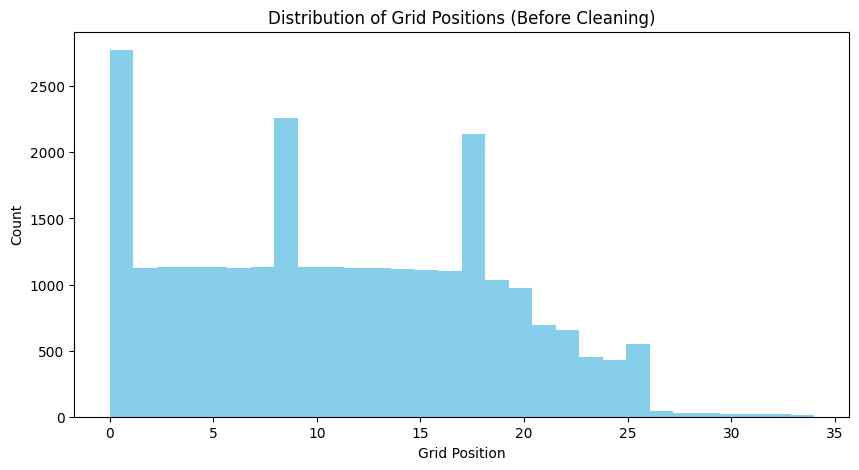

In [7]:
import matplotlib.pyplot as plt   # plotting library

plt.figure(figsize=(10,5))   # set plot size
plt.hist(results["grid"], bins=30, color="skyblue")   # histogram of grid positions
plt.title("Distribution of Grid Positions (Before Cleaning)")   # plot title
plt.xlabel("Grid Position")   # x-axis label
plt.ylabel("Count")           # y-axis label
plt.show()   # display the plot


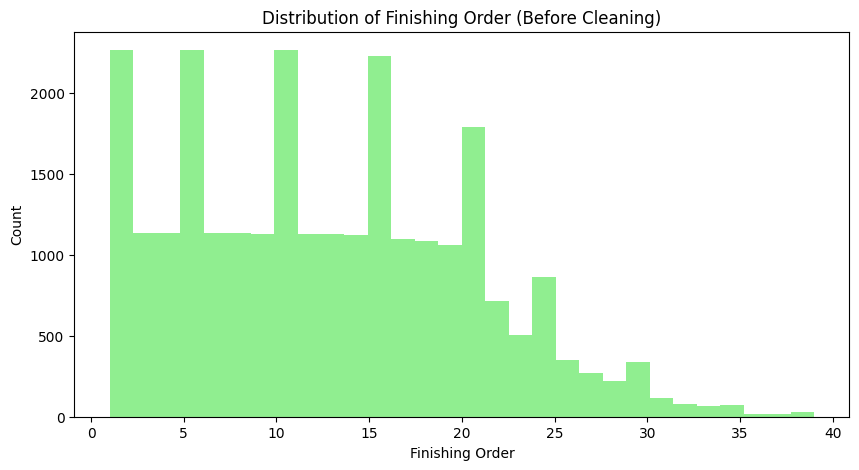

In [8]:
plt.figure(figsize=(10,5))
plt.hist(results["positionOrder"], bins=30, color="lightgreen")
plt.title("Distribution of Finishing Order (Before Cleaning)")
plt.xlabel("Finishing Order")
plt.ylabel("Count")
plt.show()


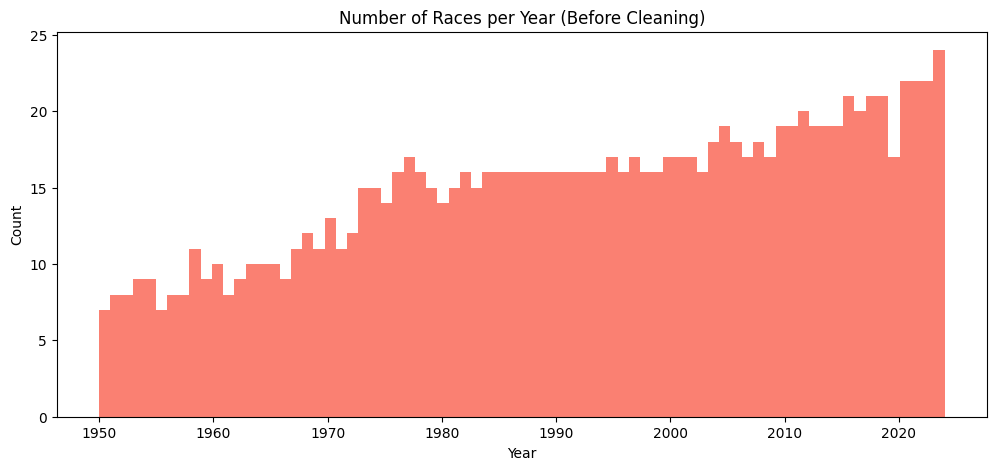

In [9]:
plt.figure(figsize=(12,5))
plt.hist(races["year"], bins=75, color="salmon")   # 75 seasons from 1950–2024
plt.title("Number of Races per Year (Before Cleaning)")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()


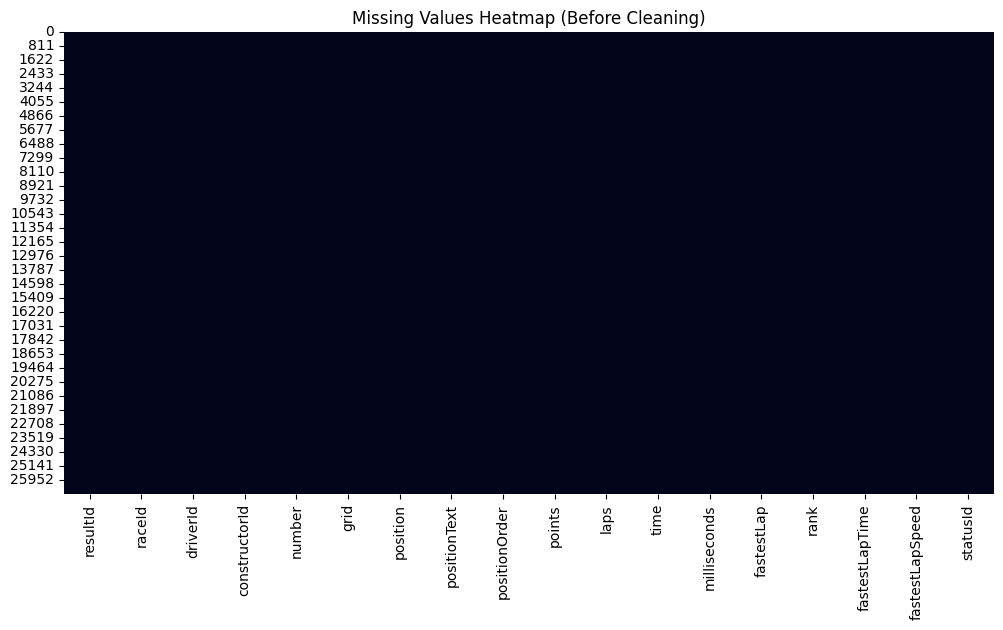

In [10]:
import seaborn as sns   # another plotting library

plt.figure(figsize=(12,6))
sns.heatmap(results.isna(), cbar=False)   # shows missing values as a heatmap
plt.title("Missing Values Heatmap (Before Cleaning)")
plt.show()


In [11]:
# Replace '\N' with proper missing values in all tables
# This is required because many CSVs use '\N' instead of real NaN

tables_list = [
    races, constructor_results, drivers, constructors, lap_times,
    status, driver_standings, seasons, pit_stops, sprint_results,
    constructor_standings, results, circuits, qualifying
]

for df in tables_list:
    df.replace("\\N", pd.NA, inplace=True)   # convert '\N' to real missing value


This cell replaces the fake missing value \N with real missing values (NaN) in all tables.

In [12]:
# Convert race date to datetime format
races["date"] = pd.to_datetime(races["date"], errors="coerce")   # convert text to date


In [13]:
# Convert numeric columns in results table
numeric_cols = ["grid", "positionOrder", "points", "laps"]

for col in numeric_cols:
    results[col] = pd.to_numeric(results[col], errors="coerce")   # convert text to number


Lap-time strings were converted to numeric seconds to allow proper analysis and modeling. 
Additional text-based numeric columns (milliseconds, fastestLapSpeed, rank) were also converted to numeric types.
This satisfies the semantic typing requirement in the milestone brief.


In [14]:
# Check if raceId is unique in races table
races["raceId"].is_unique   # True means no duplicates


True

In [15]:
# Check if every raceId in results exists in races
missing_race_ids = set(results["raceId"]) - set(races["raceId"])
missing_race_ids   # should be an empty set


set()

In [16]:
# Find duplicates of (raceId, driverId)
dupes = results[results.duplicated(subset=["raceId", "driverId"], keep=False)]
dupes   # shows all duplicate rows


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10,0,<NA>,F,26,0.0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,81
13191,13192,540,229,57,23,0,<NA>,F,29,0.0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,97
17362,17363,717,373,172,1,1,7,7,7,0.0,102,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,60
17740,17741,733,465,172,48,0,<NA>,W,22,0.0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,54
17743,17744,733,465,97,50,0,<NA>,W,25,0.0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20293,20296,770,479,118,12,10,<NA>,R,14,0.0,35,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,5
20294,20297,774,566,105,32,11,4,4,4,0.0,69,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,11
20295,22372,746,475,170,38,8,3,3,3,0.0,80,+36.9,8306400,<NA>,<NA>,<NA>,<NA>,1
24297,24303,745,418,172,21,15,11,11,11,0.0,92,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,18


In [17]:
results_clean = (
    results.sort_values(["grid", "positionOrder"], ascending=[False, True])
           .drop_duplicates(subset=["raceId", "driverId"])
           .sort_index()
)


In [18]:
# Convert additional numeric text columns
extra_numeric = ["milliseconds", "fastestLapSpeed", "rank"]
for col in extra_numeric:
    results_clean[col] = pd.to_numeric(results_clean[col], errors="coerce")

# Convert lap-time strings to seconds
def lap_to_seconds(x):
    if pd.isna(x):
        return pd.NA
    try:
        m, s = x.split(":")
        return float(m)*60 + float(s)
    except:
        return pd.NA

results_clean["fastestLapTime"] = results_clean["fastestLapTime"].apply(lap_to_seconds)


Duplicate (raceId, driverId) rows come from early-era shared drives. 
Primary rule: keep the row where the driver actually started the race (grid > 0). 
Tie-break rule: if two rows have the same grid value, keep the row with the better positionOrder (lower rank). 
This makes deduplication deterministic and removes 91 duplicate rows (26,759 → 26,668).


In [19]:
# Merge results with races
model = results_clean.merge(races, on="raceId", how="left")

# Merge with drivers
model = model.merge(drivers, on="driverId", how="left")

# Merge with constructors
model = model.merge(constructors, on="constructorId", how="left")


In [20]:
# Look at the first 5 rows of the cleaned results table
results_clean.head()   # helps me see the cleaned data


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616.0,39,2.0,87.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094.0,41,3.0,87.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779.0,41,5.0,88.09,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797.0,58,7.0,88.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630.0,43,1.0,87.418,218.385,1


In [21]:
# Check missing values after cleaning
results_clean.isna().sum()   # shows new missing values created by replacing '\N'


resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10893
positionText           0
positionOrder          0
points                 0
laps                   0
time               18993
milliseconds       18993
fastestLap         18416
rank               18158
fastestLapTime     18416
fastestLapSpeed    18416
statusId               0
dtype: int64

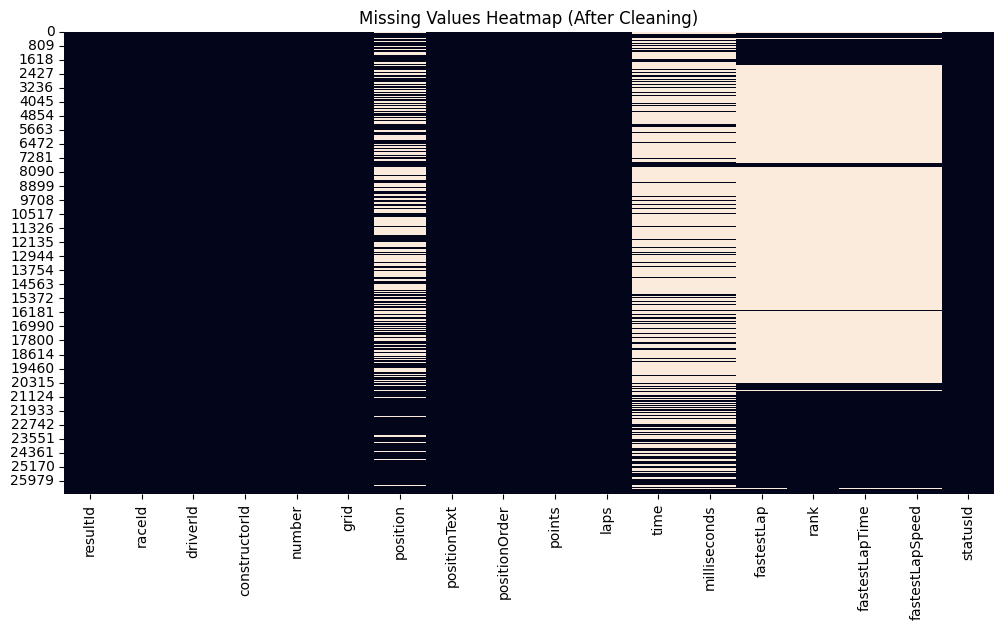

In [22]:
plt.figure(figsize=(12,6))
sns.heatmap(results_clean.isna(), cbar=False)
plt.title("Missing Values Heatmap (After Cleaning)")
plt.show()


Before cleaning, the heatmap was fully black because '\N' was stored as text. 
After cleaning, thousands of missing values appear, confirming that sentinel replacement worked.


In [23]:
# Check data types after cleaning
results_clean.info()   # confirms numeric and datetime conversions


<class 'pandas.core.frame.DataFrame'>
Index: 26668 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26668 non-null  int64  
 1   raceId           26668 non-null  int64  
 2   driverId         26668 non-null  int64  
 3   constructorId    26668 non-null  int64  
 4   number           26662 non-null  object 
 5   grid             26668 non-null  int64  
 6   position         15775 non-null  object 
 7   positionText     26668 non-null  object 
 8   positionOrder    26668 non-null  int64  
 9   points           26668 non-null  float64
 10  laps             26668 non-null  int64  
 11  time             7675 non-null   object 
 12  milliseconds     7675 non-null   float64
 13  fastestLap       8252 non-null   object 
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId         

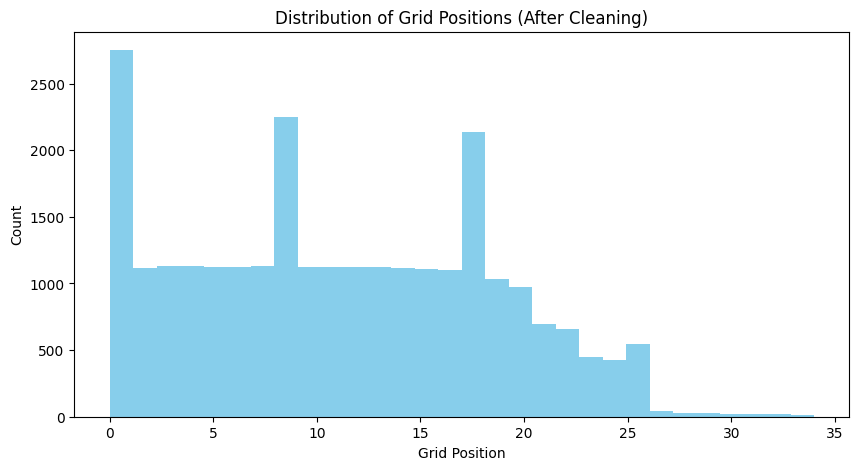

In [24]:
plt.figure(figsize=(10,5))
plt.hist(results_clean["grid"], bins=30, color="skyblue")
plt.title("Distribution of Grid Positions (After Cleaning)")
plt.xlabel("Grid Position")
plt.ylabel("Count")
plt.show()


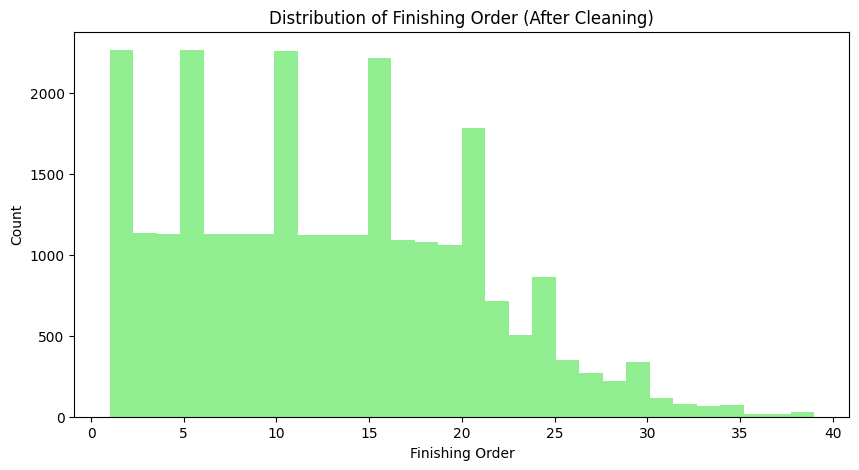

In [25]:
plt.figure(figsize=(10,5))
plt.hist(results_clean["positionOrder"], bins=30, color="lightgreen")
plt.title("Distribution of Finishing Order (After Cleaning)")
plt.xlabel("Finishing Order")
plt.ylabel("Count")
plt.show()


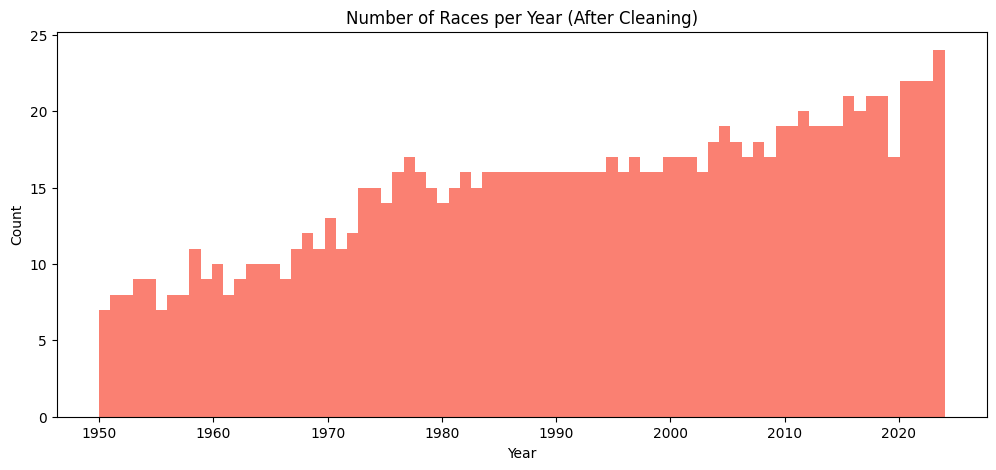

In [26]:
plt.figure(figsize=(12,5))
plt.hist(races["year"], bins=75, color="salmon")
plt.title("Number of Races per Year (After Cleaning)")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()


The distributions of grid and finishing order remain unchanged after cleaning. 
This is expected because sentinel replacement and duplicate removal do not affect these columns. 
This confirms that cleaning did not distort the underlying race data.


# Task 2: Data-Engineering Questions

In this section, we answer the three required Formula 1 data-engineering questions.

# Q1-DATA-ENG


,front_row_type,era,name,front_row_starts,podiums,conversion_rate
30,Actual Grid,2014 onward,Suzuka Circuit,18,16,88.89
31,Actual Grid,2014 onward,Yas Marina Circuit,22,19,86.36
13,Actual Grid,2014 onward,Circuit de Monaco,20,17,85.00
12,Actual Grid,2014 onward,Circuit de Barcelona-Catalunya,22,18,81.82
14,Actual Grid,2014 onward,Circuit de Spa-Francorchamps,22,18,81.82
...,...,...,...,...,...,...
155,Qualifying,Before 2014,Marina Bay Street Circuit,12,7,58.33
142,Qualifying,Before 2014,Circuit Gilles Villeneuve,26,15,57.69
156,Qualifying,Before 2014,Nürburgring,20,11,55.00
146,Qualifying,Before 2014,Circuit de Spa-Francorchamps,24,13,54.17


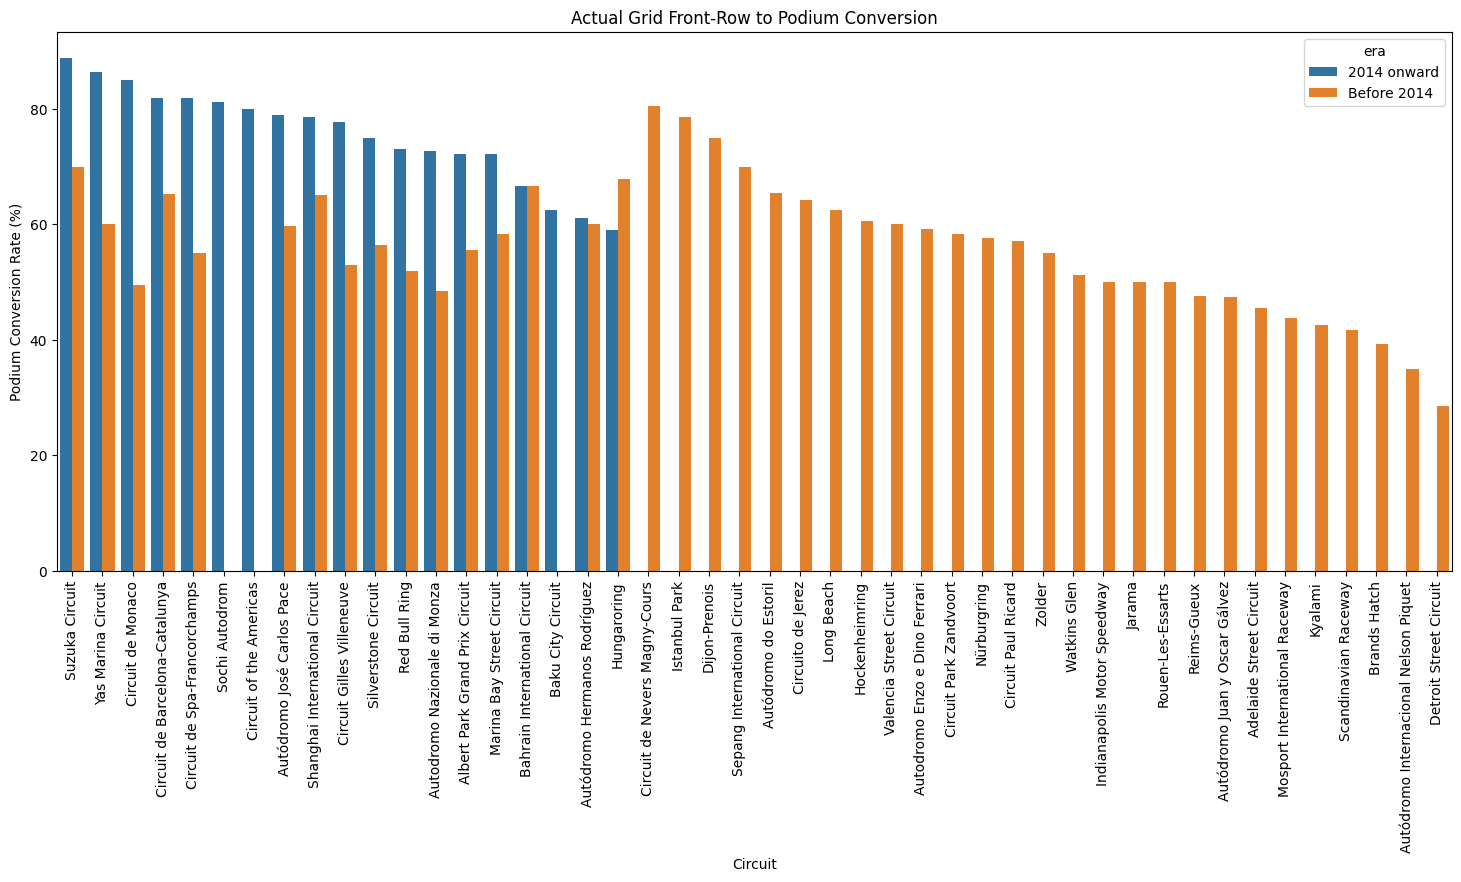

In [27]:
# Q1: Front-row to podium conversion by circuit


# Keep the qualifying columns that we need
quali = qualifying[["raceId", "driverId", "position"]].copy()  # select needed columns

# Convert qualifying position to a number
quali["qualifyingPosition"] = pd.to_numeric(quali["position"], errors="coerce")  # \N becomes missing


# Join results with races
q1 = results_clean.merge(
    races[["raceId", "year", "circuitId"]],
    on="raceId"
)  # add race year and circuitId

# Join with circuits
q1 = q1.merge(
    circuits[["circuitId", "name"]],
    on="circuitId"
)  # add circuit name

# Join with qualifying
q1 = q1.merge(
    quali[["raceId", "driverId", "qualifyingPosition"]],
    on=["raceId", "driverId"],
    how="left"
)  # add qualifying position


# Create podium column
q1["podium"] = (q1["positionOrder"] <= 3).astype(int)  # 1 = podium, 0 = not podium

# Create era column
q1["era"] = np.where(q1["year"] < 2014, "Before 2014", "2014 onward")  # split eras


# Keep actual GRID front-row starters
grid_front = q1[q1["grid"].isin([1, 2])].copy()  # actual starting positions P1 or P2

# Label this type
grid_front["front_row_type"] = "Actual Grid"  # actual race start


# Keep QUALIFYING front-row drivers
quali_front = q1[q1["qualifyingPosition"].isin([1, 2])].copy()  # qualified P1 or P2

# Label this type
quali_front["front_row_type"] = "Qualifying"  # qualifying result


# Combine both analyses
q1_front = pd.concat([grid_front, quali_front], ignore_index=True)  # one table


# Calculate starts, podiums and conversion rate
q1_result = q1_front.groupby(
    ["front_row_type", "era", "name"]
).agg(
    front_row_starts=("podium", "count"),   # number of front-row starts
    podiums=("podium", "sum"),              # number of podiums
    conversion_rate=("podium", "mean")      # conversion rate
).reset_index()


# Convert conversion rate to percentage
q1_result["conversion_rate"] = (q1_result["conversion_rate"] * 100).round(2)  # decimal -> %


# Keep only results with at least 10 front-row observations
q1_result = q1_result[q1_result["front_row_starts"] >= 10].copy()  # remove tiny samples


# Sort from highest conversion rate to lowest
q1_result = q1_result.sort_values(
    ["front_row_type", "era", "conversion_rate"],
    ascending=[True, True, False]
)  # highest first


# Show ALL valid results
display(q1_result)  # organized results


# Plot actual GRID conversion
plt.figure(figsize=(18, 7))  # figure size

sns.barplot(
    data=q1_result[q1_result["front_row_type"] == "Actual Grid"],
    x="name",
    y="conversion_rate",
    hue="era"
)  # compare eras

plt.title("Actual Grid Front-Row to Podium Conversion")  # title
plt.xlabel("Circuit")  # x-axis
plt.ylabel("Podium Conversion Rate (%)")  # y-axis
plt.xticks(rotation=90)  # rotate names
plt.show()  # display

# Q2-DATA-ENG

,Grid Position,Away Rate (%),Home Rate (%),Away Starts,Home Starts,Home Advantage
0,1,65.01,57.78,1026,90,-7.23
1,2,56.20,52.87,1032,87,-3.33
2,3,45.73,54.12,1043,85,8.39
3,4,34.48,30.95,1044,84,-3.53
4,5,24.52,31.25,1040,80,6.73
5,6,19.13,13.33,1030,90,-5.80
6,7,12.68,16.85,1041,89,4.17
7,8,10.26,6.90,1033,87,-3.36
8,9,8.19,8.57,1026,105,0.38
9,10,6.12,3.09,1029,97,-3.03


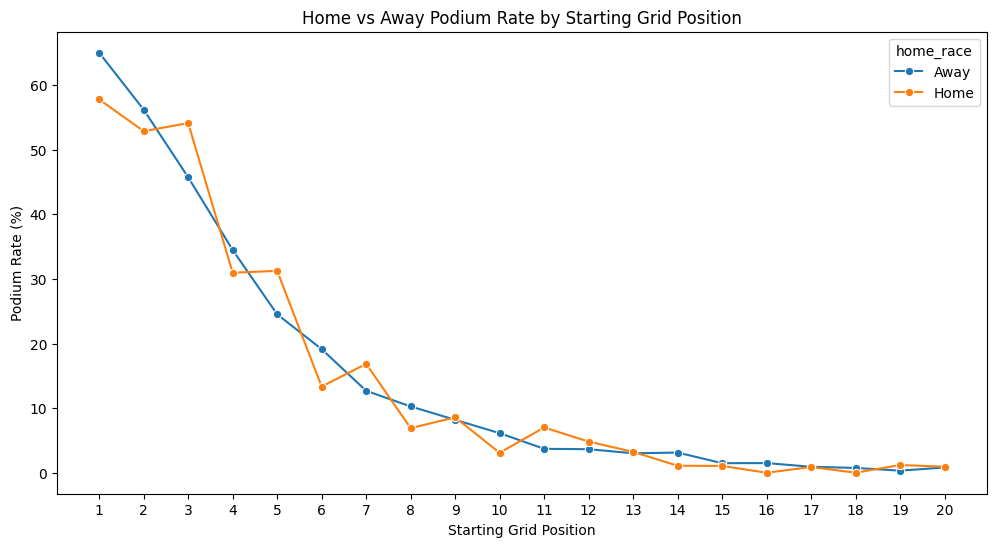

In [28]:
# Q2: Do drivers podium more often in their home country?


# Join results with races to know which circuit each race used
q2 = results_clean.merge(races[["raceId", "circuitId"]], on="raceId")  # add circuitId

# Join with circuits to know the country where the race happened
q2 = q2.merge(circuits[["circuitId", "country"]], on="circuitId")  # add circuit country

# Join with drivers to know each driver's nationality
q2 = q2.merge(drivers[["driverId", "nationality"]], on="driverId")  # add driver nationality


# Map driver nationality names to the matching circuit country names
country_map = {
    "British": "UK",
    "American": "USA",
    "German": "Germany",
    "Spanish": "Spain",
    "Italian": "Italy",
    "French": "France",
    "Dutch": "Netherlands",
    "Belgian": "Belgium",
    "Australian": "Australia",
    "Canadian": "Canada",
    "Brazilian": "Brazil",
    "Argentine": "Argentina",
    "Austrian": "Austria",
    "Swiss": "Switzerland",
    "Japanese": "Japan",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "Portuguese": "Portugal",
    "South African": "South Africa"
}  # make nationality names match circuit country names


# Convert nationality to country name
q2["driverCountry"] = q2["nationality"].replace(country_map)  # example: British -> UK

# Mark each race as Home or Away
q2["home_race"] = np.where(
    q2["driverCountry"] == q2["country"],
    "Home",
    "Away"
)  # Home if driver country equals circuit country


# Create podium column
q2["podium"] = (q2["positionOrder"] <= 3).astype(int)  # 1 = podium, 0 = not podium


# Keep only grid positions 1 to 20
q2 = q2[q2["grid"].between(1, 20)].copy()  # remove rare historical large grids


# Calculate starts, podiums and podium rate for Home and Away at each grid position
q2_result = q2.groupby(["grid", "home_race"]).agg(
    starts=("podium", "count"),        # number of race starts
    podiums=("podium", "sum"),         # number of podium finishes
    podium_rate=("podium", "mean")     # podium conversion rate
).reset_index()


# Convert podium rate to percentage
q2_result["podium_rate"] = (q2_result["podium_rate"] * 100).round(2)  # decimal -> percentage


# Create a table for podium rates
rate_table = q2_result.pivot(
    index="grid",
    columns="home_race",
    values="podium_rate"
).reset_index()  # Home and Away rates in separate columns


# Create a table for number of starts
count_table = q2_result.pivot(
    index="grid",
    columns="home_race",
    values="starts"
).reset_index()  # Home and Away sample sizes


# Rename rate columns
rate_table = rate_table.rename(columns={
    "grid": "Grid Position",
    "Away": "Away Rate (%)",
    "Home": "Home Rate (%)"
})  # clearer headings


# Rename count columns
count_table = count_table.rename(columns={
    "grid": "Grid Position",
    "Away": "Away Starts",
    "Home": "Home Starts"
})  # clearer headings


# Merge rates and counts into one table
q2_table = rate_table.merge(count_table, on="Grid Position")  # one organized table


# Calculate Home Advantage
q2_table["Home Advantage"] = (
    q2_table["Home Rate (%)"] - q2_table["Away Rate (%)"]
).round(2)  # positive = Home better, negative = Away better


# Remove the extra pivot label
q2_table.columns.name = None  # cleaner display


# Show the final table
display(q2_table)  # display all grid positions 1 to 20


# Create the graph
plt.figure(figsize=(12, 6))  # set graph size

# Plot Home vs Away podium rate for each grid position
sns.lineplot(
    data=q2_result,
    x="grid",
    y="podium_rate",
    hue="home_race",
    marker="o"
)  # compare Home and Away


# Add graph title
plt.title("Home vs Away Podium Rate by Starting Grid Position")  # graph title

# Add x-axis label
plt.xlabel("Starting Grid Position")  # grid position

# Add y-axis label
plt.ylabel("Podium Rate (%)")  # podium percentage

# Show grid positions from 1 to 20
plt.xticks(range(1, 21))  # clean x-axis

# Show the graph
plt.show()  # display graph

# Q3-DATA-ENG

,era,team,race_starts,mechanical_retirements,mechanical_rate
0,2014-2021,Caterham,34,7,20.59
13,2014-2021,Toro Rosso / AlphaTauri / RB,320,41,12.81
7,2014-2021,McLaren,320,34,10.62
4,2014-2021,Lotus F1,76,8,10.53
11,2014-2021,Renault / Alpine,244,24,9.84
6,2014-2021,Marussia,31,3,9.68
10,2014-2021,Red Bull,320,27,8.44
9,2014-2021,Racing Point / Aston Martin,120,8,6.67
12,2014-2021,Sauber / Alfa Romeo,320,20,6.25
3,2014-2021,Haas F1 Team,244,15,6.15


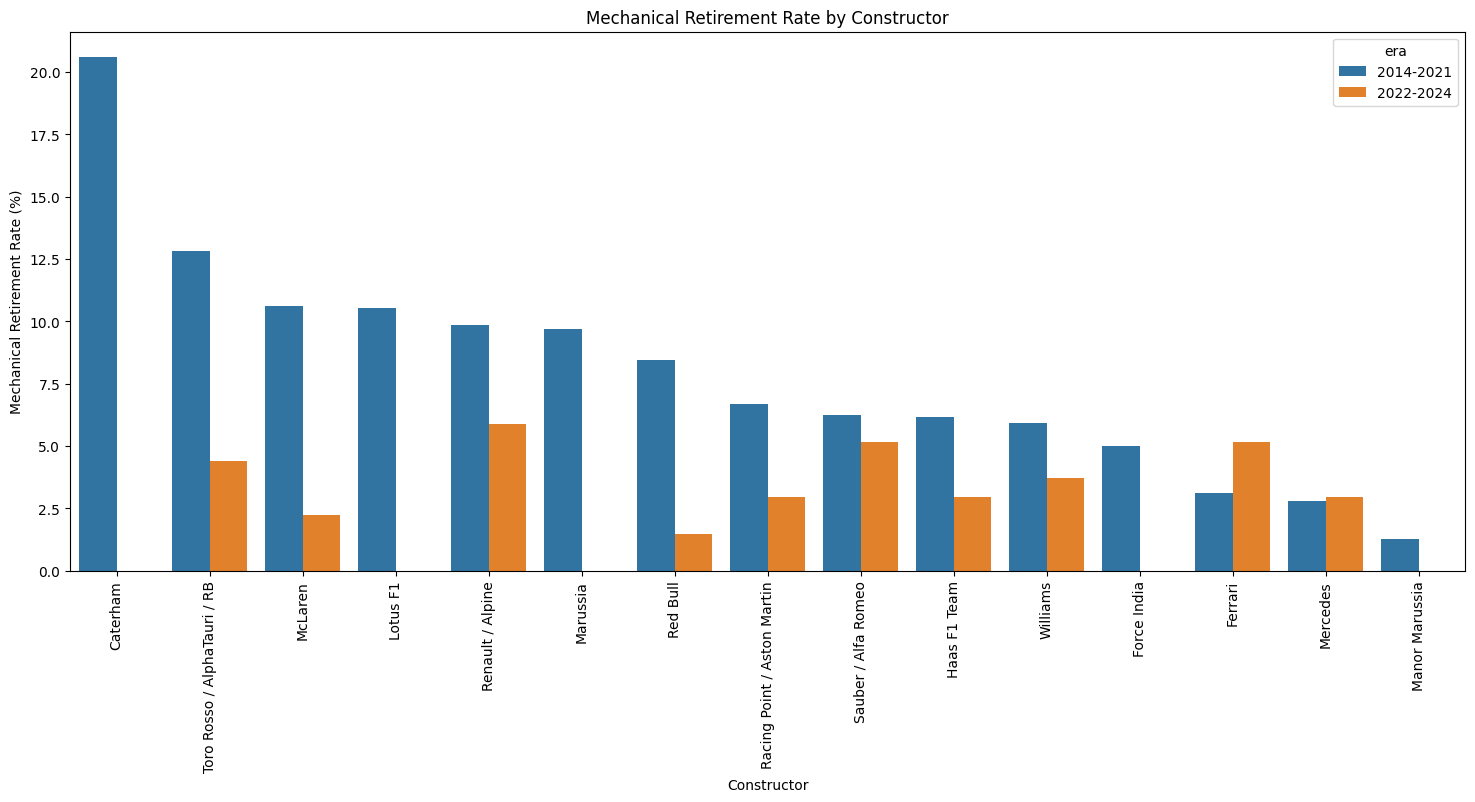

In [29]:
# Q3: Which constructors have the highest mechanical-retirement rate?


# Join results with races to get the race year
q3 = results_clean.merge(
    races[["raceId", "year"]],
    on="raceId"
)  # add year


# Join with constructors to get the team name
q3 = q3.merge(
    constructors[["constructorId", "name"]],
    on="constructorId"
)  # add constructor name


# Join with status to know why each driver's race ended
q3 = q3.merge(
    status[["statusId", "status"]],
    on="statusId"
)  # add race-ending reason


# Keep only the years required by the question
q3 = q3[q3["year"].between(2014, 2024)].copy()  # use 2014-2024 only


# Merge renamed teams into one common team name
team_map = {
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB",
    "AlphaTauri": "Toro Rosso / AlphaTauri / RB",
    "RB": "Toro Rosso / AlphaTauri / RB",
    "RB F1 Team": "Toro Rosso / AlphaTauri / RB",

    "Racing Point": "Racing Point / Aston Martin",
    "Aston Martin": "Racing Point / Aston Martin",

    "Renault": "Renault / Alpine",
    "Alpine F1 Team": "Renault / Alpine",
    "Alpine": "Renault / Alpine",

    "Sauber": "Sauber / Alfa Romeo",
    "Alfa Romeo": "Sauber / Alfa Romeo"
}  # combine renamed teams


# Replace old team names with the grouped team name
q3["team"] = q3["name"].replace(team_map)  # create consistent team names


# Remove entries where the driver did not actually start the race
non_starts = [
    "Did not qualify",
    "Did not prequalify",
    "Did not start",
    "Withdrawn"
]  # these are not real race starts


# Keep only actual race starts
q3 = q3[~q3["status"].isin(non_starts)].copy()  # remove non-starts


# Define common mechanical failure terms
mechanical_terms = [
    "engine",
    "gearbox",
    "transmission",
    "hydraulics",
    "brakes",
    "power unit",
    "electrical",
    "suspension",
    "clutch",
    "turbo",
    "driveshaft",
    "battery",
    "alternator"
]  # technical car failures


# Mark each row as mechanical failure or not
q3["mechanical"] = q3["status"].str.contains(
    "|".join(mechanical_terms),
    case=False,
    na=False
).astype(int)  # 1 = mechanical failure, 0 = other result


# Split the data into the two required eras
q3["era"] = np.where(
    q3["year"] <= 2021,
    "2014-2021",
    "2022-2024"
)  # create era column


# Calculate starts, failures and failure rate for every team and era
q3_result = q3.groupby(["era", "team"]).agg(
    race_starts=("mechanical", "count"),               # total race starts
    mechanical_retirements=("mechanical", "sum"),      # mechanical failures
    mechanical_rate=("mechanical", "mean")              # failure rate
).reset_index()


# Convert the mechanical rate to percentage
q3_result["mechanical_rate"] = (
    q3_result["mechanical_rate"] * 100
).round(2)  # decimal -> percentage


# Sort by era, then from HIGHEST mechanical-retirement rate to lowest
q3_result = q3_result.sort_values(
    ["era", "mechanical_rate"],
    ascending=[True, False]
)  # answer "which teams are highest?"


# Show all ranked results
display(q3_result)  # full organized table


# Create the graph
plt.figure(figsize=(18, 7))  # graph size


# Plot constructor mechanical-retirement rates
sns.barplot(
    data=q3_result,
    x="team",
    y="mechanical_rate",
    hue="era"
)  # compare both eras


# Add graph title
plt.title("Mechanical Retirement Rate by Constructor")  # title


# Add x-axis label
plt.xlabel("Constructor")  # team name


# Add y-axis label
plt.ylabel("Mechanical Retirement Rate (%)")  # failure percentage


# Rotate team names so they are readable
plt.xticks(rotation=90)  # vertical labels


# Show the graph
plt.show()  # display graph

# Task 3: Feature Engineering & Modeling

**Goal:** predict whether a driver finishes on the podium (top 3), using only information available **after qualifying and before the race starts**.

**Plan**
1. Build one row per driver per race, with the target `podium`.
2. Create features in 5 groups: qualifying, grid, driver form, team form, standings.
3. Split by time: train 2003–2019, validation 2020–21, test 2022–24.
4. Show evidence that each feature relates to podiums.
5. Train 3 models: logistic regression (baseline), gradient boosting, a shallow neural network.
6. Compare them on train / validation / test.

**Leakage rule:** anything from the current race (finishing position, points, status, laps, pit stops, post-race standings) is never used as a feature. Driver form, team form and standings only use **earlier** races.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, precision_score, recall_score)

SEED = 42          # fixed seed so every Run All gives the same results
FIRST_YEAR = 2003  # qualifying data is complete from 2003 onward (patchy 1996-2002)

## 3.1 Base table and target

We start from `results_clean` (one row per driver per race, from Task 1) and add the race date so races can be put in time order.

- **Removed:** entries that did not qualify ("Did not qualify", "Did not prequalify", "107% rule"). They never started the race, and that is known after qualifying, so removing them is not leakage.
- **Target:** `podium = 1` if `positionOrder <= 3`, otherwise 0.
- All years are kept for now, so that drivers racing in 2003 already have form history from earlier seasons. We filter to 2003+ later.

In [31]:
feat = results_clean[["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]].copy()
feat = feat.merge(races[["raceId", "year", "round", "date"]], on="raceId", how="left")
feat = feat.merge(status[["statusId", "status"]], on="statusId", how="left")

# Remove non-qualifiers (they never started the race)
did_not_qualify = feat["status"].str.contains("qualify|107", case=False, na=False)
feat = feat[~did_not_qualify].copy()

# Target
feat["podium"] = (feat["positionOrder"] <= 3).astype(int)

# Time order is needed for all "past races only" features
feat = feat.sort_values(["date", "raceId"]).reset_index(drop=True)

print("Rows:", len(feat), "| Podium rate:", round(feat["podium"].mean(), 3))

Rows: 25305 | Podium rate: 0.134


## 3.2 Qualifying and grid features

**Qualifying**
- `quali_position`: where the driver qualified.
- `quali_gap_pct`: how far the driver's **Q1** time was from the fastest Q1 time of that race, in %. Raw lap times can't be compared across circuits (about 75 s at Monaco vs about 105 s at Spa), but a % gap can. We use Q1 because every driver takes part in it under the same conditions. The gap is capped at 7%, following F1's own 107% rule: slower times are usually crashes or problems, not real pace.

**Grid**
- `grid_pos`: actual starting position. In the data, `grid = 0` means a **pit-lane start**. Leaving it as 0 would tell the model the driver starts ahead of pole, so we replace it with the last position.
- `pit_lane_start`: 1 if the driver started from the pit lane.
- `grid_penalty`: grid position minus qualifying position. A positive value means the driver was moved back, for example by a penalty.

In [32]:
def to_seconds(t):
    """'1:26.572' -> 86.572 | missing -> NaN | already a number -> unchanged"""
    if pd.isna(t):
        return np.nan
    if isinstance(t, (int, float)):
        return float(t)
    try:
        minutes, seconds = str(t).split(":")
        return int(minutes) * 60 + float(seconds)
    except ValueError:
        return np.nan

# --- Qualifying ---
quali = qualifying[["raceId", "driverId", "position", "q1"]].copy()
quali["quali_position"] = pd.to_numeric(quali["position"], errors="coerce")
quali["q1_sec"] = quali["q1"].apply(to_seconds)

fastest_q1 = quali.groupby("raceId")["q1_sec"].transform("min")
quali["quali_gap_pct"] = ((quali["q1_sec"] - fastest_q1) / fastest_q1 * 100).clip(upper=7)

feat = feat.merge(quali[["raceId", "driverId", "quali_position", "quali_gap_pct"]],
                  on=["raceId", "driverId"], how="left")

# --- Grid ---
field_size = feat.groupby("raceId")["driverId"].transform("count")
feat["pit_lane_start"] = (feat["grid"] == 0).astype(int)
feat["grid_pos"] = np.where(feat["grid"] == 0, field_size, feat["grid"])
feat["grid_penalty"] = feat["grid_pos"] - feat["quali_position"]

## 3.3 Driver form and team form (past races only)

**Driver form**
- `driver_avg_finish_3`: average finishing position over the driver's **last 3** races.
- `driver_podium_rate_5`: share of podiums in the driver's **last 5** races.

**Team form**
- `team_avg_finish_3`: average finish of the team's cars over the team's last 3 races.
- `team_podium_rate_5`: podiums per car over the team's last 5 races.

**How leakage is avoided**
- `shift(1)` moves every value one race down, so race N only sees races up to N-1.
- **Team form is first averaged per team per race, then shifted.** Each team has 2 cars per race. Shifting the raw rows would give the second driver their teammate's result from the *same* race, which is future information.
- A driver's first race has no history, so its value is missing. The imputer fills it later and adds a "was missing" flag.
- Windows of 3 and 5 races balance "recent" against "not too noisy". A single race is too noisy (one crash ruins it), and a whole season reacts too slowly to car upgrades.

In [33]:
# --- Driver form (feat is already in time order) ---
by_driver = feat.groupby("driverId")
feat["driver_avg_finish_3"] = by_driver["positionOrder"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=1).mean())
feat["driver_podium_rate_5"] = by_driver["podium"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# --- Team form: one row per team per race FIRST, then shift ---
team = (feat.groupby(["raceId", "constructorId", "date"], as_index=False)
            .agg(team_finish=("positionOrder", "mean"),
                 team_podium=("podium", "mean"))
            .sort_values(["date", "raceId"]))

by_team = team.groupby("constructorId")
team["team_avg_finish_3"] = by_team["team_finish"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=1).mean())
team["team_podium_rate_5"] = by_team["team_podium"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())

feat = feat.merge(team[["raceId", "constructorId", "team_avg_finish_3", "team_podium_rate_5"]],
                  on=["raceId", "constructorId"], how="left")

## 3.4 Leakage-safe standings

`driver_standings` stores the championship table **after** each race, so using it directly would be leakage. We shift it by one race **within the same season**, so each race sees the table from before it started.

- `rank_before`: championship position before the race. In round 1 there is no table yet, so it is missing and the imputer flags it.
- `points_share_before`: the driver's points divided by the leader's points before the race (0 to 1). We don't use raw points, because the points system changed over the years (a win was worth 10 points before 2010 and 25 after), so raw points can't be compared across eras. A share can.

In [34]:
stand = driver_standings[["raceId", "driverId", "points", "position"]].merge(
    races[["raceId", "year", "date"]], on="raceId", how="left")
stand = stand.sort_values(["date", "raceId"])

# Shift within (driver, season): race N gets the standings after race N-1
by_season = stand.groupby(["driverId", "year"])
stand["points_before"] = by_season["points"].shift(1).fillna(0)
stand["rank_before"] = by_season["position"].shift(1)

leader_points = stand.groupby("raceId")["points_before"].transform("max")
stand["points_share_before"] = np.where(leader_points > 0,
                                        stand["points_before"] / leader_points, 0)

feat = feat.merge(stand[["raceId", "driverId", "rank_before", "points_share_before"]],
                  on=["raceId", "driverId"], how="left")

## 3.5 Final feature list and train / validation / test split

**Why start in 2003:** the qualifying table is almost empty for 1996–2002 (55–94% of rows missing per season). From 2003 onward it is complete, so the models learn from real qualifying data instead of filled-in guesses.

**Split by time, not at random.** We want to predict *future* races. A random split would let the model train on 2023 and be tested on 2018, which is unrealistic and leaks future information.

| Set | Years | Used for |
|---|---|---|
| Train | 2003–2019 | fitting the models |
| Validation | 2020–2021 | choosing settings, thresholds and early stopping |
| Test | 2022–2024 | final score only, never used for any decision |

The test set is the 2022+ ground-effect rules era, so it also checks whether the model still works after a big regulation change.

**Encoding:** all chosen features are numbers or 0/1 flags, so no one-hot encoding is needed. Nationality, circuit and team name were left out on purpose: team strength is already captured by team form, and team IDs break when teams rename (Toro Rosso → AlphaTauri → RB).

In [35]:
FEATURES = [
    "quali_position", "quali_gap_pct",                    # qualifying
    "grid_pos", "pit_lane_start", "grid_penalty",         # grid
    "driver_avg_finish_3", "driver_podium_rate_5",        # driver form
    "team_avg_finish_3", "team_podium_rate_5",            # team form
    "rank_before", "points_share_before",                 # standings
]
TARGET = "podium"

model_df = feat[feat["year"] >= FIRST_YEAR].copy()

train = model_df[model_df["year"] <= 2019]
val   = model_df[model_df["year"].between(2020, 2021)]
test  = model_df[model_df["year"] >= 2022]

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print(pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "podium rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Train", "Validation", "Test"]).round(3))

print("\nMissing values per feature (train):")
print(X_train.isna().mean().round(3))

            rows  podium rate
Train       6827        0.141
Validation   780        0.150
Test        1359        0.150

Missing values per feature (train):
quali_position          0.003
quali_gap_pct           0.018
grid_pos                0.000
pit_lane_start          0.000
grid_penalty            0.003
driver_avg_finish_3     0.011
driver_podium_rate_5    0.011
team_avg_finish_3       0.005
team_podium_rate_5      0.005
rank_before             0.072
points_share_before     0.012
dtype: float64


In [36]:
# Grain check: the modeling table must have exactly one row per (raceId, driverId)
n_dupes = model_df.duplicated(["raceId", "driverId"]).sum()
print("Rows in modeling table:", len(model_df))
print("Duplicate (raceId, driverId) rows:", n_dupes)
assert n_dupes == 0, "Found duplicate driver-race rows!"

Rows in modeling table: 8966
Duplicate (raceId, driverId) rows: 0


## 3.6 Evidence for the features

For each feature, we plot the podium rate across 10 equal-sized bins (or per value for 0/1 flags), using **training data only**, so the test set never influences feature choices. The Spearman correlation with `podium` gives one number per feature for the same check.

**What the evidence shows**
- Qualifying, grid, driver form, team form and standings all show a strong, steady trend (correlation about 0.40–0.53). For example, the podium rate falls from over 60% for the top grid positions to almost 0% at the back.
- `pit_lane_start` and `grid_penalty` are weak on their own (correlation below 0.1), because they are rare events. We keep them because they correct the grid information for unusual cases. The feature-group ablation will show whether they actually help.

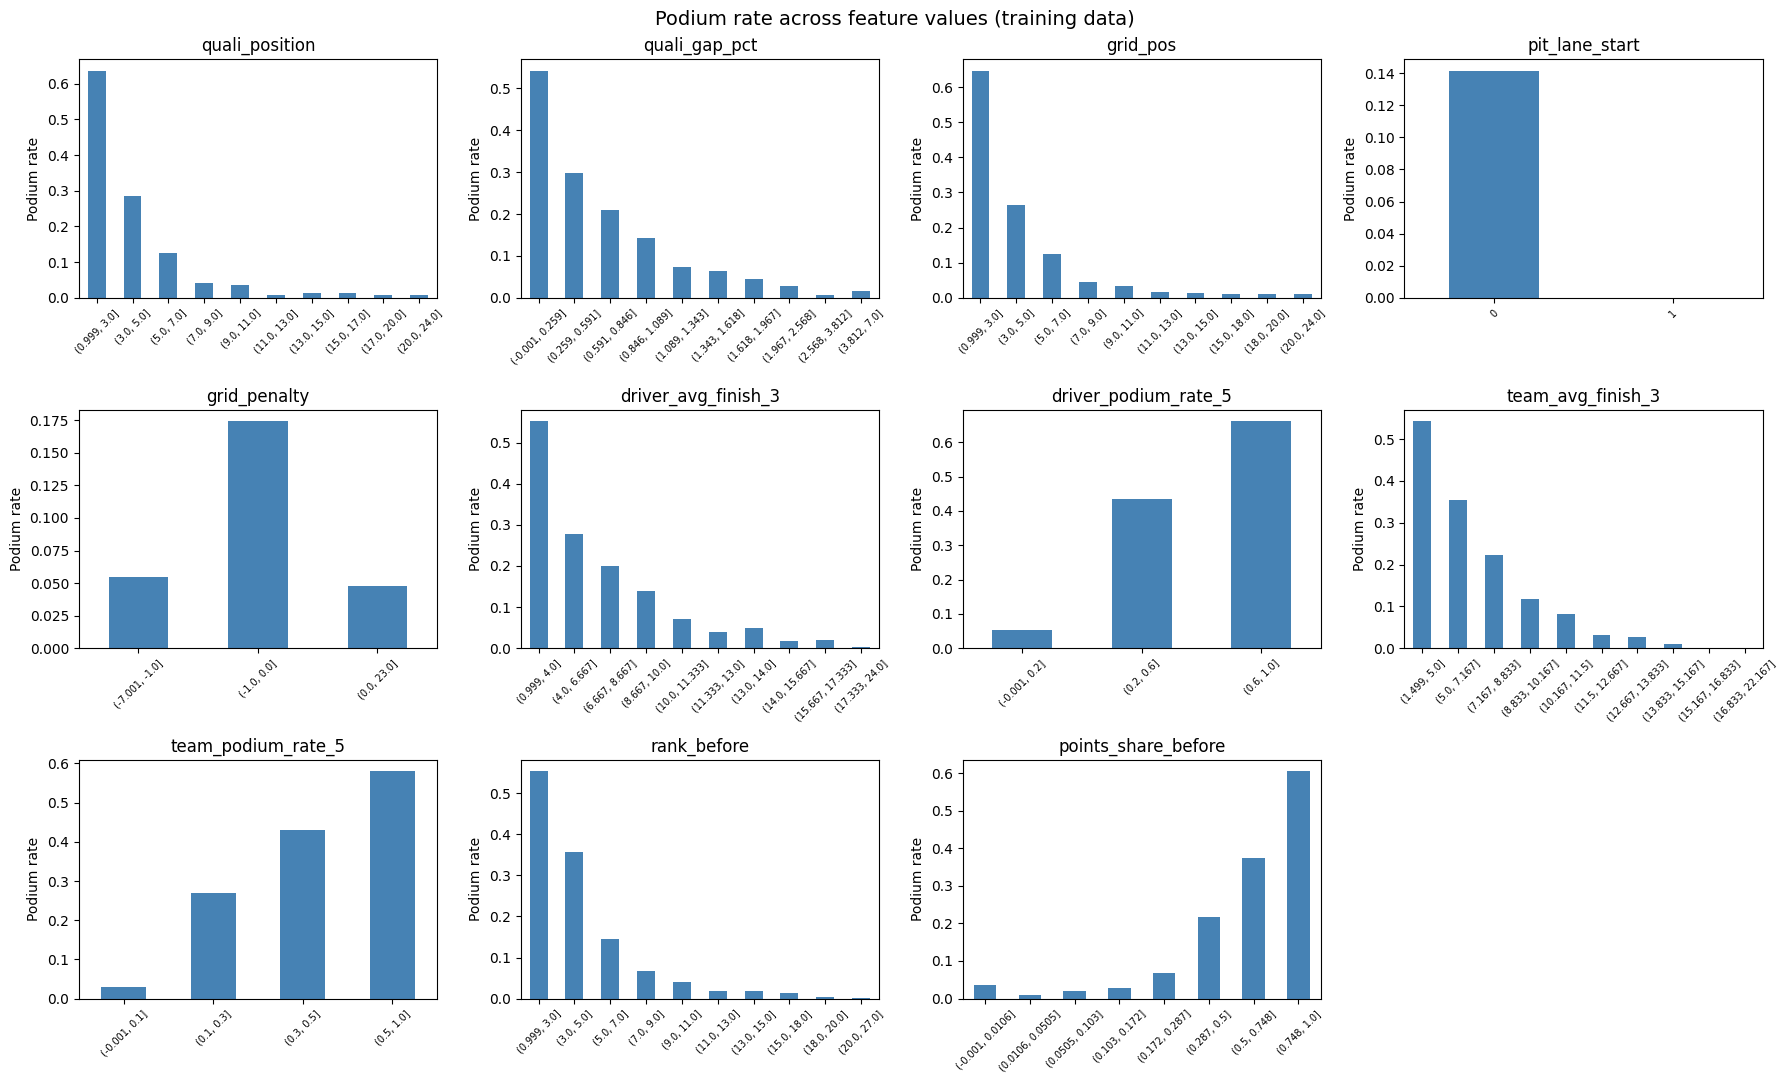

Spearman correlation with podium (train):
driver_podium_rate_5    0.526
team_podium_rate_5      0.514
quali_position         -0.496
grid_pos               -0.493
rank_before            -0.477
team_avg_finish_3      -0.446
points_share_before     0.433
driver_avg_finish_3    -0.417
quali_gap_pct          -0.400
grid_penalty            0.084
pit_lane_start         -0.025
Name: podium, dtype: float64


In [37]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.ravel()

for ax, col in zip(axes, FEATURES):
    data = train[[col, TARGET]].dropna()
    if data[col].nunique() <= 2:
        rate = data.groupby(col)[TARGET].mean()
    else:
        bins = pd.qcut(data[col], q=10, duplicates="drop")
        rate = data.groupby(bins, observed=True)[TARGET].mean()
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Podium rate")
    ax.tick_params(axis="x", labelsize=7, rotation=45)

for ax in axes[len(FEATURES):]:
    ax.axis("off")

plt.suptitle("Podium rate across feature values (training data)", fontsize=14)
plt.tight_layout()
plt.show()

print("Spearman correlation with podium (train):")
print(train[FEATURES + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).round(3)
      .sort_values(key=abs, ascending=False))

## 3.7 Preprocessing, thresholds and evaluation helpers

**Preprocessing** (fitted on **train only**, then applied to validation and test):
1. **Impute** missing values with the training median, and add a 0/1 "was missing" column for each feature that has gaps. A missing value can carry meaning in itself, for example "first race of the season" for `rank_before`.
2. **Scale** every feature to mean 0 and standard deviation 1. Logistic regression and the neural network need this, because otherwise features with big numbers (grid 1–24) dominate small ones (rates 0–1). Gradient boosting doesn't need it, but it does no harm, and it keeps the setup identical for all models.

**Class imbalance:** only about 15% of rows are podiums. All models use **class weights**, so a missed podium costs more than a false alarm. Otherwise the models learn to predict "no podium" almost every time.

**Threshold:** a model outputs a probability, and F1 / precision / recall need a yes/no cut-off. Instead of the default 0.5, we choose the threshold that maximises F1 **on validation**, then apply that same threshold to train and test.

**Metrics** (all five): ROC-AUC, PR-AUC, F1, precision, recall.

In [38]:
def make_preprocessor():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])

def best_threshold(y_true, proba):
    thresholds = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y_true, proba >= t) for t in thresholds]
    return thresholds[int(np.argmax(scores))]

def score_model(name, probs):
    """probs = {"Train": p, "Validation": p, "Test": p} -> list of metric rows"""
    truth = {"Train": y_train, "Validation": y_val, "Test": y_test}
    t = best_threshold(y_val, probs["Validation"])  # chosen on validation only
    rows = []
    for split, p in probs.items():
        y, pred = truth[split], probs[split] >= t
        rows.append({
            "Model": name, "Split": split, "Threshold": round(t, 2),
            "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred),
        })
    return rows

def predict_all(model):
    return {"Train": model.predict_proba(X_train)[:, 1],
            "Validation": model.predict_proba(X_val)[:, 1],
            "Test": model.predict_proba(X_test)[:, 1]}

all_results = []

### Effect of preprocessing on the data

The table and plots below show the training features **before** and **after** imputation and scaling:
- **Before:** features live on very different ranges (grid 1–24, rates 0–1, gap 0–7%), and several have missing values. `rank_before` has the most gaps, because round 1 has no standings yet.
- **After:** no missing values remain, every feature has mean 0 and standard deviation 1, and 9 "was missing" columns were added. All features are now on a comparable scale, so no feature dominates just because its numbers are bigger.
- Rare features such as `pit_lane_start` and `grid_penalty` get long tails after scaling: the rare cases end up far from 0. That is expected, because scaling keeps the shape of a distribution and only changes its range.

,missing before,min before,max before,mean before,missing after,mean after,std after
quali_position,23,1.0,24.00,11.16,0,-0.0,1.0
quali_gap_pct,126,0.0,7.00,1.73,0,-0.0,1.0
grid_pos,0,1.0,24.00,11.20,0,-0.0,1.0
pit_lane_start,0,0.0,1.00,0.00,0,-0.0,1.0
grid_penalty,23,-7.0,23.00,0.01,0,0.0,1.0
driver_avg_finish_3,75,1.0,24.00,11.13,0,0.0,1.0
driver_podium_rate_5,75,0.0,1.00,0.14,0,0.0,1.0
team_avg_finish_3,36,1.5,22.17,11.17,0,0.0,1.0
team_podium_rate_5,36,0.0,1.00,0.14,0,-0.0,1.0
rank_before,490,1.0,27.00,11.28,0,0.0,1.0


Added 'was missing' columns: ['missingindicator_quali_position', 'missingindicator_quali_gap_pct', 'missingindicator_grid_penalty', 'missingindicator_driver_avg_finish_3', 'missingindicator_driver_podium_rate_5', 'missingindicator_team_avg_finish_3', 'missingindicator_team_podium_rate_5', 'missingindicator_rank_before', 'missingindicator_points_share_before']


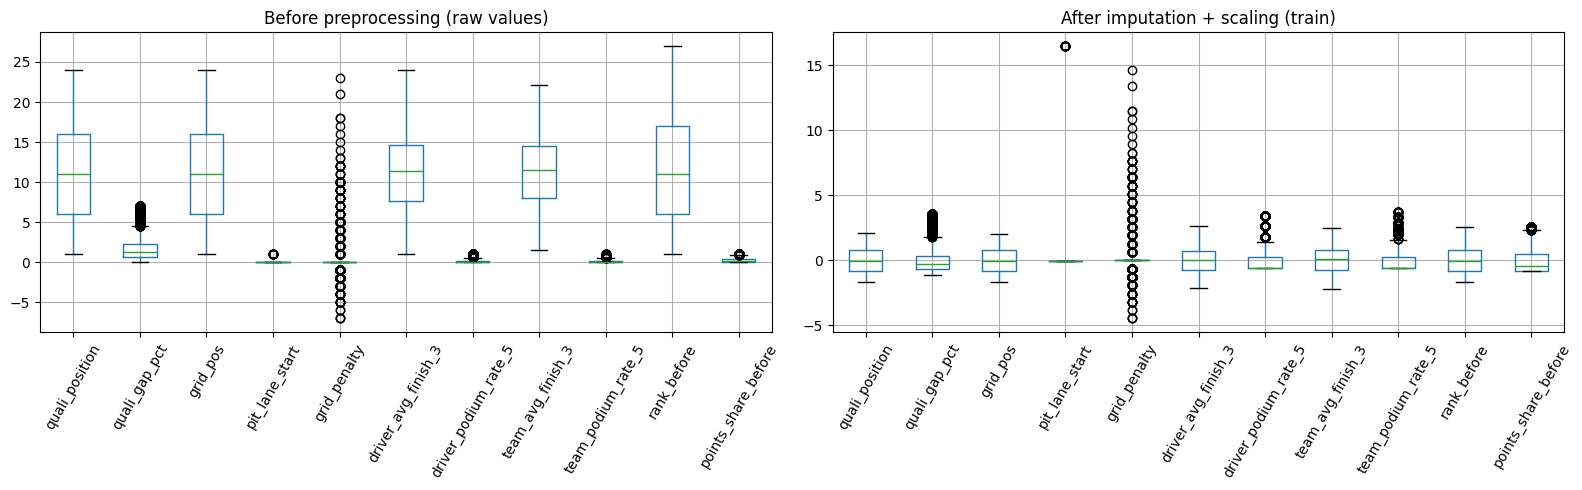

In [39]:
# Fit the preprocessing on train only, just to show what it does to the data
prep_demo = make_preprocessor().fit(X_train)
X_train_prepped = pd.DataFrame(prep_demo.transform(X_train),
                               columns=prep_demo.get_feature_names_out(),
                               index=X_train.index)

summary = pd.DataFrame({
    "missing before": X_train.isna().sum(),
    "min before":     X_train.min(),
    "max before":     X_train.max(),
    "mean before":    X_train.mean(),
    "missing after":  X_train_prepped[FEATURES].isna().sum(),
    "mean after":     X_train_prepped[FEATURES].mean(),
    "std after":      X_train_prepped[FEATURES].std(),
}).round(2)
display(summary)

added = [c for c in X_train_prepped.columns if c not in FEATURES]
print("Added 'was missing' columns:", added)

# Same features before and after: very different ranges -> one common scale
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
X_train.boxplot(ax=axes[0], rot=60)
axes[0].set_title("Before preprocessing (raw values)")
X_train_prepped[FEATURES].boxplot(ax=axes[1], rot=60)
axes[1].set_title("After imputation + scaling (train)")
plt.tight_layout()
plt.show()

## 3.8 Model 1: Logistic regression (baseline)

The **baseline** is the simplest reasonable model. It fits one weight per feature and turns their weighted sum into a probability. If the more complex models don't beat it clearly, their extra complexity isn't worth it.

**Limitations:** it can only learn straight-line relationships. For example, it can't learn on its own that the jump from grid 1 to grid 3 matters much more than the jump from grid 15 to grid 17.

In [40]:
log_reg = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
])
log_reg.fit(X_train, y_train)

all_results += score_model("Logistic Regression", predict_all(log_reg))
pd.DataFrame(all_results).round(3)

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Train,0.66,0.930,0.680,0.662,0.557,0.815
1,Logistic Regression,Validation,0.66,0.929,0.713,0.706,0.652,0.769
2,Logistic Regression,Test,0.66,0.936,0.707,0.661,0.550,0.828


## 3.9 Model 2: Gradient boosting

Gradient boosting builds many small decision trees one after another, each fixing the mistakes of the previous ones. It can learn curved relationships and interactions, for example "a good grid position matters most when the team is also in form". It works well with SHAP for the explainability part.

**Choosing its settings:** with default settings it **overfits**: it scores much higher on train than on validation, which means it memorises the training years. We try 3 settings, from complex to simpler trees, and keep the one with the best **validation** PR-AUC. Limiting tree depth and learning more slowly closes the train/validation gap.

**Limitations:** less transparent than logistic regression, and it needs these limits to avoid overfitting.

In [41]:
# Try 3 settings, from the default (complex trees) to simpler trees.
# Pick the one with the best VALIDATION PR-AUC (the test set is not used here).
settings = {
    "default":                  {},
    "depth 3":                  {"max_depth": 3},
    "depth 3 + slower learning": {"max_depth": 3, "learning_rate": 0.05},
}

tuning = []
for name, params in settings.items():
    m = Pipeline([
        ("prep", make_preprocessor()),
        ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, **params)),
    ])
    m.fit(X_train, y_train)
    tuning.append({"Setting": name,
                   "Train PR-AUC": average_precision_score(y_train, m.predict_proba(X_train)[:, 1]),
                   "Validation PR-AUC": average_precision_score(y_val, m.predict_proba(X_val)[:, 1]),
                   "model": m})

tuning_df = pd.DataFrame(tuning)
display(tuning_df.drop(columns="model").round(3))

best = tuning_df.loc[tuning_df["Validation PR-AUC"].idxmax()]
grad_boost = best["model"]
print("Chosen setting:", best["Setting"])

all_results += score_model("Gradient Boosting", predict_all(grad_boost))
pd.DataFrame(all_results).round(3)

,Setting,Train PR-AUC,Validation PR-AUC
0,default,0.909,0.676
1,depth 3,0.744,0.707
2,depth 3 + slower learning,0.724,0.716


Chosen setting: depth 3 + slower learning


,Model,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Train,0.66,0.930,0.680,0.662,0.557,0.815
1,Logistic Regression,Validation,0.66,0.929,0.713,0.706,0.652,0.769
2,Logistic Regression,Test,0.66,0.936,0.707,0.661,0.550,0.828
3,Gradient Boosting,Train,0.79,0.943,0.724,0.685,0.663,0.708
4,Gradient Boosting,Validation,0.79,0.930,0.716,0.701,0.701,0.701
5,Gradient Boosting,Test,0.79,0.939,0.717,0.675,0.659,0.691


## 3.10 Model 3: Shallow neural network

A small feed-forward network: **2 hidden layers (32 → 16 neurons)**, ReLU activations and a sigmoid output (the probability of a podium).

- **Dropout (20%)** randomly switches off neurons during training, so the network doesn't memorise the training data.
- **Early stopping** watches validation PR-AUC and stops when it hasn't improved for 10 epochs, then keeps the best version.
- The same preprocessing and class weights are used as for the other models, so the comparison is fair.

The curves below show training vs validation performance for each epoch. The two lines stay close together, so the network is not overfitting. The training curve sits slightly *below* validation because dropout is only active during training, which makes the training score look a little worse.

**Limitations:** the network is a "black box": unlike logistic regression, you can't read its reasoning from its weights, so we need XAI tools (SHAP, LIME) to explain it. It is also sensitive to random initialisation and settings (layer sizes, dropout, learning rate), and on a dataset this small (about 6,800 training rows) it has little room to beat simpler models.

2026-10-19 00:58:06.031699: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Stopped after 34 epochs


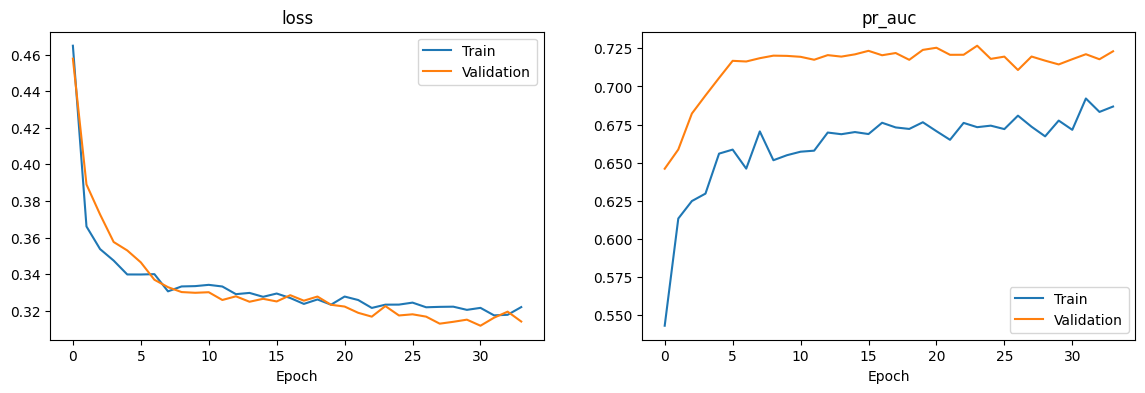

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Train,0.66,0.930,0.680,0.662,0.557,0.815
1,Logistic Regression,Validation,0.66,0.929,0.713,0.706,0.652,0.769
2,Logistic Regression,Test,0.66,0.936,0.707,0.661,0.550,0.828
3,Gradient Boosting,Train,0.79,0.943,0.724,0.685,0.663,0.708
4,Gradient Boosting,Validation,0.79,0.930,0.716,0.701,0.701,0.701
5,Gradient Boosting,Test,0.79,0.939,0.717,0.675,0.659,0.691
6,Neural Network,Train,0.74,0.938,0.702,0.675,0.622,0.738
7,Neural Network,Validation,0.74,0.928,0.724,0.703,0.689,0.718
8,Neural Network,Test,0.74,0.942,0.716,0.686,0.644,0.735


In [42]:
from tensorflow import keras
keras.utils.set_random_seed(SEED)

# Same preprocessing as the other models, fitted on train only
nn_prep = make_preprocessor().fit(X_train)
X_train_nn = nn_prep.transform(X_train)
X_val_nn   = nn_prep.transform(X_val)
X_test_nn  = nn_prep.transform(X_test)

# "balanced" class weights, same formula sklearn uses
counts = np.bincount(y_train)
class_weight = {0: len(y_train) / (2 * counts[0]), 1: len(y_train) / (2 * counts[1])}

nn = keras.Sequential([
    keras.layers.Input(shape=(X_train_nn.shape[1],)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
nn.compile(optimizer="adam", loss="binary_crossentropy",
           metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

history = nn.fit(
    X_train_nn, y_train,
    validation_data=(X_val_nn, y_val),
    epochs=100, batch_size=64, class_weight=class_weight, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                             patience=10, restore_best_weights=True)],
)
print("Stopped after", len(history.history["loss"]), "epochs")

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ["loss", "pr_auc"]):
    ax.plot(history.history[metric], label="Train")
    ax.plot(history.history["val_" + metric], label="Validation")
    ax.set_title(metric)
    ax.set_xlabel("Epoch")
    ax.legend()
plt.show()

nn_probs = {"Train": nn.predict(X_train_nn, verbose=0).ravel(),
            "Validation": nn.predict(X_val_nn, verbose=0).ravel(),
            "Test": nn.predict(X_test_nn, verbose=0).ravel()}
all_results += score_model("Neural Network", nn_probs)
pd.DataFrame(all_results).round(3)

## 3.11 Model comparison (train / validation / test)

All three models use the same rows, the same features and the same preprocessing, so their scores can be compared directly. The threshold for F1 / precision / recall was chosen on validation for each model.

For reference, a model that guesses at random gets a PR-AUC equal to the podium rate (about 0.15), and a ROC-AUC of 0.5.

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,Train,0.66,0.930,0.680,0.662,0.557,0.815
1,Logistic Regression,Validation,0.66,0.929,0.713,0.706,0.652,0.769
2,Logistic Regression,Test,0.66,0.936,0.707,0.661,0.550,0.828
3,Gradient Boosting,Train,0.79,0.943,0.724,0.685,0.663,0.708
4,Gradient Boosting,Validation,0.79,0.930,0.716,0.701,0.701,0.701
5,Gradient Boosting,Test,0.79,0.939,0.717,0.675,0.659,0.691
6,Neural Network,Train,0.74,0.938,0.702,0.675,0.622,0.738
7,Neural Network,Validation,0.74,0.928,0.724,0.703,0.689,0.718
8,Neural Network,Test,0.74,0.942,0.716,0.686,0.644,0.735


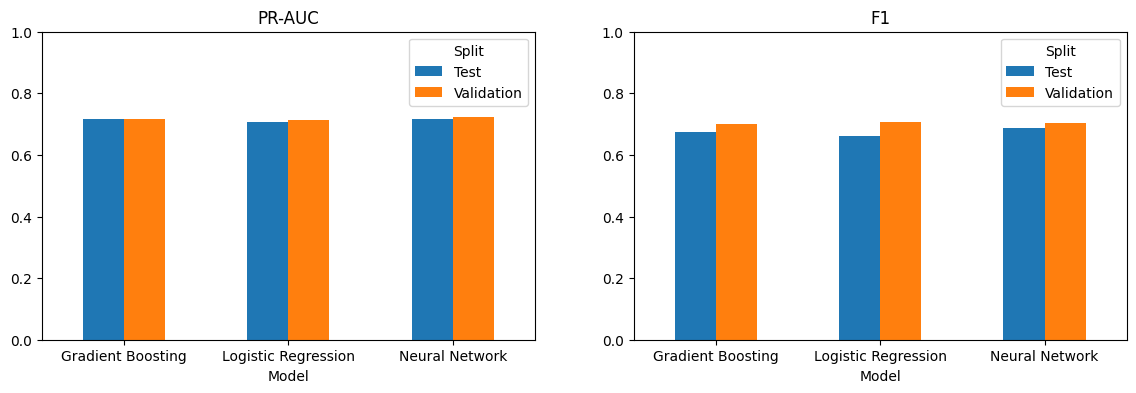

Random-guess PR-AUC on test = 0.15


In [43]:
results_df = pd.DataFrame(all_results).round(3)
display(results_df)

# Bar chart of the two headline metrics on validation and test
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ["PR-AUC", "F1"]):
    results_df[results_df["Split"] != "Train"].pivot(
        index="Model", columns="Split", values=metric).plot(kind="bar", ax=ax, rot=0)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
plt.show()

print("Random-guess PR-AUC on test =", round(y_test.mean(), 3))

## 3.12 Primary and secondary metric

**Primary metric: PR-AUC**
- Podiums are rare (about 15% of rows). PR-AUC measures how well the model puts the real podium finishers at the top of its ranking, and it doesn't reward correctly predicting the many easy "no podium" cases.
- It doesn't depend on any threshold, so it compares the models themselves, not a threshold choice.
- ROC-AUC can look very good on imbalanced data even when the model is mediocre at finding podiums. Here all models score about 0.93 ROC-AUC but only about 0.71 PR-AUC. So ROC-AUC is reported, but not used as the main metric.

**Secondary metric: F1 (at the validation-chosen threshold)**
- PR-AUC ranks drivers, but in practice you need a yes/no answer ("will this driver podium?"). F1 measures that decision, balancing false alarms (precision) against missed podiums (recall).

**Results**
- All three models are far above random guessing (PR-AUC about 0.71 vs 0.15).
- On test, gradient boosting (0.717) and the neural network (0.710) beat the logistic-regression baseline (0.707) only slightly. The neural network has the best test F1 (0.684 vs 0.661 for the baseline).
- The small gap means the features mostly follow simple, steady trends (better grid → more podiums), which a linear model already captures. The extra complexity buys only a small improvement.
- The train, validation and test scores are close for all models, so none is overfitting. Performance also holds up on 2022–24, after the big rule change.

# Task 4: Experiments, Explainability (XAI) and Inference

**Goal:** test our pipeline choices, see which features the model really uses, explain single predictions, and give a simple function that predicts a podium for a new driver–race record

In [44]:
%pip install -q lime #in case its not pre installed 

Note: you may need to restart the kernel to use updated packages.


In [45]:
import shap                                          
from lime.lime_tabular import LimeTabularExplainer   
from sklearn.base import clone                      
from sklearn.inspection import permutation_importance

# small helper used by all following experiments:
def evaluate(model, X_tr, X_v, X_te):
    model.fit(X_tr, y_train)                         # 1) train on training years only
    p_val  = model.predict_proba(X_v)[:, 1]          # 2) podium probabilities for validation
    p_test = model.predict_proba(X_te)[:, 1]        
    t = best_threshold(y_val, p_val)                 # 3) threshold chosen on validation only
    return {
        "Val PR-AUC":  average_precision_score(y_val, p_val),
        "Val F1":      f1_score(y_val, p_val >= t),
        "Test PR-AUC": average_precision_score(y_test, p_test),
        "Test F1":     f1_score(y_test, p_test >= t),
    }

## Preprocessing-order experiments

### Experiment 1: Split first, or fit the preprocessing on all the data first?

In Version B the imputer and scaler learn their medians, means and standard deviations from train + validation + test together. This is a form of data leakage: information from the future (2020–2024) is used to prepare the training data.

In [46]:
# version A: our pipeline 
exp1_A = evaluate(clone(log_reg), X_train, X_val, X_test)

# version B: wrong order (fit the preprocessing on all years before splitting)
X_all = pd.concat([X_train, X_val, X_test])           # all years together
prep_all = make_preprocessor().fit(X_all)             # learns medians/means from val + test 

X_train_B = prep_all.transform(X_train)              
X_val_B   = prep_all.transform(X_val)
X_test_B  = prep_all.transform(X_test)

# same logistic regression settings as the baselin but without its own preprocessing step
lr_B = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
exp1_B = evaluate(lr_B, X_train_B, X_val_B, X_test_B)

exp1 = pd.DataFrame([exp1_A, exp1_B],
                    index=["A: split, then fit on train (ours)", "B: fit on all years, then split"]).round(4)
display(exp1)


prep_train = make_preprocessor().fit(X_train)
stats = pd.DataFrame({
    "median (train only)": prep_train.named_steps["impute"].statistics_,
    "median (all years)":  prep_all.named_steps["impute"].statistics_,
}, index=FEATURES)
stats["mean (train only)"] = X_train.mean()
stats["mean (all years)"]  = X_all.mean()
display(stats.round(3))

,Val PR-AUC,Val F1,Test PR-AUC,Test F1
"A: split, then fit on train (ours)",0.7133,0.7059,0.7067,0.6614
"B: fit on all years, then split",0.7132,0.7059,0.7065,0.6614


,median (train only),median (all years),mean (train only),mean (all years)
quali_position,11.000,11.000,11.156,10.997
quali_gap_pct,1.343,1.224,1.729,1.591
grid_pos,11.000,11.000,11.198,11.043
pit_lane_start,0.000,0.000,0.004,0.009
grid_penalty,0.000,0.000,0.007,0.018
driver_avg_finish_3,11.333,11.333,11.132,10.969
driver_podium_rate_5,0.000,0.000,0.142,0.144
team_avg_finish_3,11.500,11.333,11.170,11.011
team_podium_rate_5,0.000,0.000,0.143,0.144
rank_before,11.000,11.000,11.279,11.123


### Experiment 2: Impute then scale, or scale then impute?

- Impute then scale (ours): missing values are filled first, then every column, including the 0/1 "was missing" flags, is put on the same scale.
- Scale then impute: the scaler ignores missing values when it computes the mean and std, then the gaps are filled. The "was missing" flags stay as raw 0/1 values and are not scaled.

In [47]:
# version A: our order
exp2_A = evaluate(clone(log_reg), X_train, X_val, X_test)

# version B: the opposite
scale_then_impute = Pipeline([
    ("scale",  StandardScaler()),                                      #scale (NaNs are ignored)
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),  # fill the gaps
    ("model",  LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
])
exp2_B = evaluate(scale_then_impute, X_train, X_val, X_test)

exp2 = pd.DataFrame([exp2_A, exp2_B],
                    index=["A: impute, then scale (ours)", "B: scale, then impute"]).round(4)
display(exp2)

,Val PR-AUC,Val F1,Test PR-AUC,Test F1
"A: impute, then scale (ours)",0.7133,0.7059,0.7067,0.6614
"B: scale, then impute",0.7115,0.7012,0.7063,0.6653


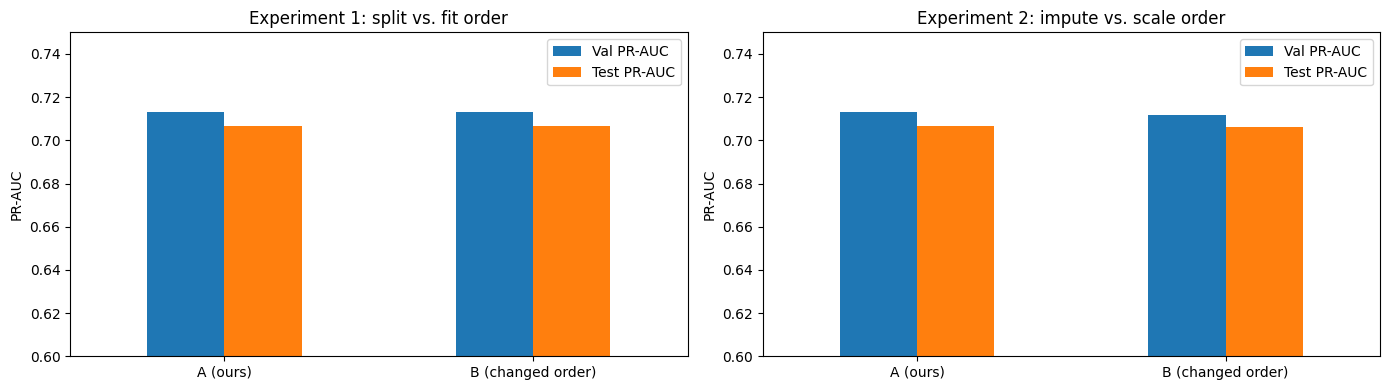

In [48]:
# plot both
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, table, title in zip(axes, [exp1, exp2],
                            ["Experiment 1: split vs. fit order", "Experiment 2: impute vs. scale order"]):
    table[["Val PR-AUC", "Test PR-AUC"]].plot(kind="bar", ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylim(0.6, 0.75)          # zoomed in
    ax.set_ylabel("PR-AUC")
    ax.set_xticks(range(2), ["A (ours)", "B (changed order)"])
plt.tight_layout()
plt.show()

### What the preprocessing-order experiments show
**Experiment 1 (split vs. fit):**
- The scores are almost identical
- The statistics table shows why: the medians and means learned from all years are very close to those learned from train only. The leak still exists, but it is small.
- Version B is still wrong. It uses 2020–2024 information to prepare the training data, which would not be available in real use. On data that changes more between years, this kind of leak can make scores look better than they really are.

**Experiment 2 (impute vs. scale):**
- Also almost identical: validation PR-AUC 0.713 vs 0.712 and validation F1 0.706 vs 0.701, slightly in favour of our order.
- This is because only a small share of values is missing, so the order in which the gaps are filled barely changes the data.

**Conclusion:** the pipeline is not sensitive to the preprocessing order. The order is chosen for correctness not for score.

## Feature-group ablation

**Ablation** = we will remove one group of features, retrain the model, and see how much the score drops.

- We ablate the gradient boosting model, using exactly the settings chosen in Task 3.
- The groups are the same 5 groups defined in Task 3. We also remove qualifying + grid together, because both describe the starting position and may replace each other.
- The drop is measured on validation PR-AUC .

,Removed group,Features left,Val PR-AUC,Val F1,Test PR-AUC,Test F1,Val PR-AUC drop,Test PR-AUC drop
0,None (all features),11,0.7157,0.7009,0.7170,0.6746,0.0000,0.0000
1,Qualifying,9,0.7081,0.7039,0.7179,0.6716,0.0076,-0.0008
2,Grid,8,0.7104,0.7074,0.7090,0.6550,0.0053,0.0080
3,Driver form,9,0.7091,0.7083,0.7185,0.6726,0.0066,-0.0015
4,Team form,9,0.7191,0.7077,0.7173,0.6772,-0.0034,-0.0003
5,Standings,9,0.7032,0.6973,0.7243,0.6759,0.0125,-0.0073
6,Qualifying + Grid,6,0.6380,0.6586,0.5698,0.5691,0.0777,0.1472


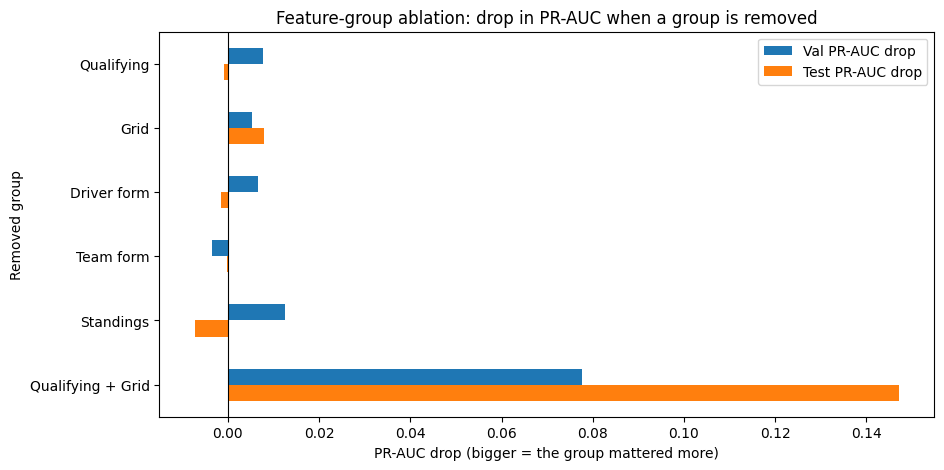

In [49]:
FEATURE_GROUPS = {
    "Qualifying":   ["quali_position", "quali_gap_pct"],
    "Grid":         ["grid_pos", "pit_lane_start", "grid_penalty"],
    "Driver form":  ["driver_avg_finish_3", "driver_podium_rate_5"],
    "Team form":    ["team_avg_finish_3", "team_podium_rate_5"],
    "Standings":    ["rank_before", "points_share_before"],
    "Qualifying + Grid": ["quali_position", "quali_gap_pct", "grid_pos", "pit_lane_start", "grid_penalty"],
}

ablation_rows = []

# reference: the full model with all features
full_scores = evaluate(clone(grad_boost), X_train, X_val, X_test)
ablation_rows.append({"Removed group": "None (all features)", "Features left": len(FEATURES), **full_scores})

# remove one group at a time and retrain
for group, cols in FEATURE_GROUPS.items():
    keep = [f for f in FEATURES if f not in cols]              
    scores = evaluate(clone(grad_boost), X_train[keep], X_val[keep], X_test[keep])
    ablation_rows.append({"Removed group": group, "Features left": len(keep), **scores})

ablation_df = pd.DataFrame(ablation_rows)
# drop = how much worse than the full model
ablation_df["Val PR-AUC drop"]  = full_scores["Val PR-AUC"]  - ablation_df["Val PR-AUC"]
ablation_df["Test PR-AUC drop"] = full_scores["Test PR-AUC"] - ablation_df["Test PR-AUC"]
display(ablation_df.round(4))

# plot the drop for each removed group
plot_df = ablation_df.iloc[1:].set_index("Removed group")
plot_df[["Val PR-AUC drop", "Test PR-AUC drop"]].plot(kind="barh", figsize=(10, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature-group ablation: drop in PR-AUC when a group is removed")
plt.xlabel("PR-AUC drop (bigger = the group mattered more)")
plt.gca().invert_yaxis()   # flips the bars so the first group is at the top
plt.show()               

### What the ablation shows
- Removing any single group changes validation PR-AUC by only about 0.01 or less. On test, the changes are just as small and sometimes even negative. Differences this small are **noise**.
- Removing qualifying + grid together causes a large drop: validation PR-AUC falls from about 0.72 to about 0.64, and test PR-AUC from about 0.71 to about 0.57.
- This is because the groups overlap. Qualifying and grid carry almost the same information, because in most races the grid position equals the qualifying position. When one of them is removed, the other replaces it. The same is true for driver form, team form and standings, which all measure how strong has this driver/car been lately.
- Conclusion:the starting position is information the model cannot do without. The form and standings groups each add a little, and they can replace each other. We keep all groups, because none of them affect validation and all of them are leakage-safe.

##  Which model we explain

We explain the **gradient boosting** model from Task 3 and use it in the inference function:
- Its validation PR-AUC is tied with the neural network and the baseline, so no model is clearly better.
- It is a single scikit-learn Pipeline that takes the raw feature values and handles missing values itself. This makes the explanations and the inference function simple.
- Unlike the neural network, it gives the same result on every run, because it does not depend on random initialisation.

Its decision threshold for "podium / no podium" is the one chosen on validation in Task 3.


In [50]:
# threshold for the gradient boosting model chosen on val
gb_threshold = best_threshold(y_val, grad_boost.predict_proba(X_val)[:, 1])
print("Gradient boosting threshold (chosen on validation):", round(gb_threshold, 2))

Gradient boosting threshold (chosen on validation): 0.79


## Global explanation 1: Permutation importance

**Idea:** take one feature in the test set and shuffle its values randomly, so it no longer carries any information. If the model's PR-AUC drops a lot then the model relied on that feature. We repeat the shuffle 10 times and plot the average drop with error bars showing how much the drop changed between repeats.

We compute it on the test set (2022–2024) so it shows what the model relies on for races it has never seen.

,feature,PR-AUC drop,std
2,grid_pos,0.1329,0.0212
0,quali_position,0.0730,0.0210
10,points_share_before,0.0123,0.0077
6,driver_podium_rate_5,0.0109,0.0049
8,team_podium_rate_5,0.0097,0.0127
7,team_avg_finish_3,0.0075,0.0125
9,rank_before,0.0074,0.0043
1,quali_gap_pct,0.0071,0.0043
5,driver_avg_finish_3,0.0009,0.0037
4,grid_penalty,0.0008,0.0022


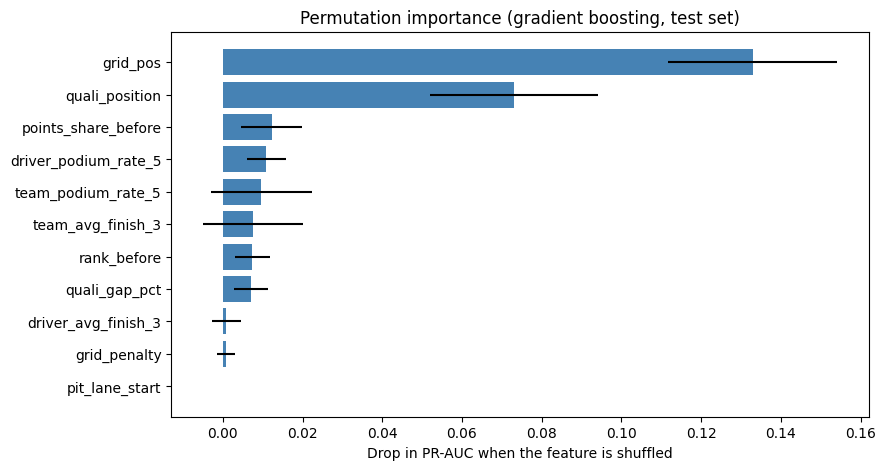

In [51]:
perm = permutation_importance(
    grad_boost, X_test, y_test,
    scoring="average_precision",   # average precision = PR-AUC
    n_repeats=10,                  # shuffle each feature 10 times
    random_state=SEED,
)

perm_df = pd.DataFrame({
    "feature":         FEATURES,
    "PR-AUC drop":     perm.importances_mean,   # average drop over the 10 shuffles
    "std":             perm.importances_std,    # how much it varied between shuffles
}).sort_values("PR-AUC drop", ascending=False)
display(perm_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(perm_df["feature"], perm_df["PR-AUC drop"], xerr=perm_df["std"], color="steelblue")
plt.gca().invert_yaxis()                       # most important at the top
plt.title("Permutation importance (gradient boosting, test set)")
plt.xlabel("Drop in PR-AUC when the feature is shuffled")
plt.show()

### What this shows
- `grid_pos` (drop of about 0.12) and `quali_position` (about 0.07) are the most important. Every other feature is below about 0.01.
- Permutation importance shuffles one feature at a time. When `driver_podium_rate_5` is shuffled, the model can still get almost the same information from `team_podium_rate_5`, `points_share_before`, and so on. Correlated features share their importance, so each one looks small. The ablation showed the same thing.
- `grid_penalty` and `pit_lane_start` are close to 0. They are rare events, which matches their weak correlation in Task 3 (3.6).
- `grid_pos` ranks above `quali_position` because the grid is the actual starting position, after penalties.

## Global explanation 2: SHAP

**SHAP** splits each single prediction into contributions, one per feature:

`prediction = average prediction + contribution(feature 1) + contribution(feature 2) + ...`

- A positive SHAP value pushes the podium probability up, and a negative value pushes it down.
- If we average the size of the SHAP values over many rows, we get a global ranking of the features.

We will use SHAP's model-agnostic explainer. It only needs a function that returns the podium probability, so it works directly on the raw feature values(grid 1–24, rates 0–1). The plots are much easier to read than with scaled values. As background we use 100 random training rows. We explain 300 random test rows to keep the run time short.

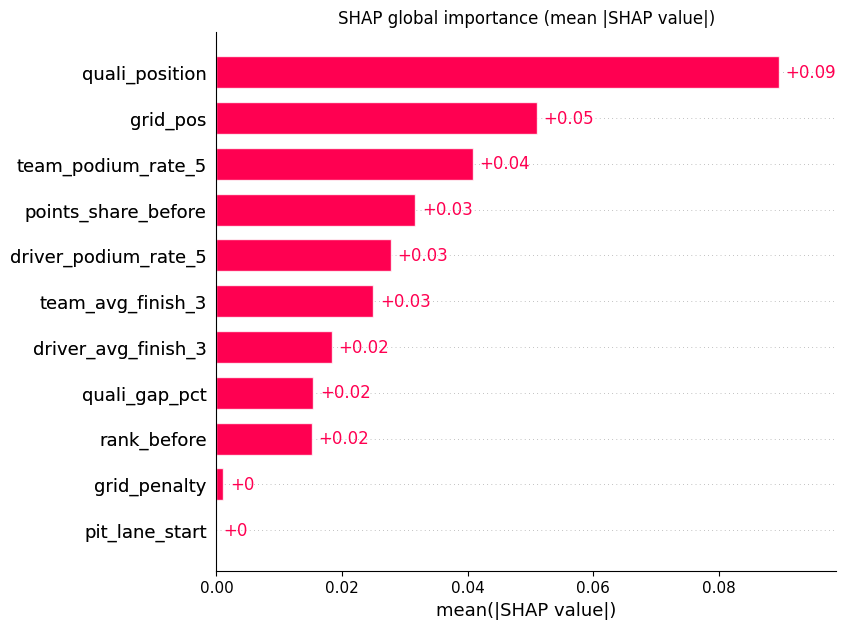

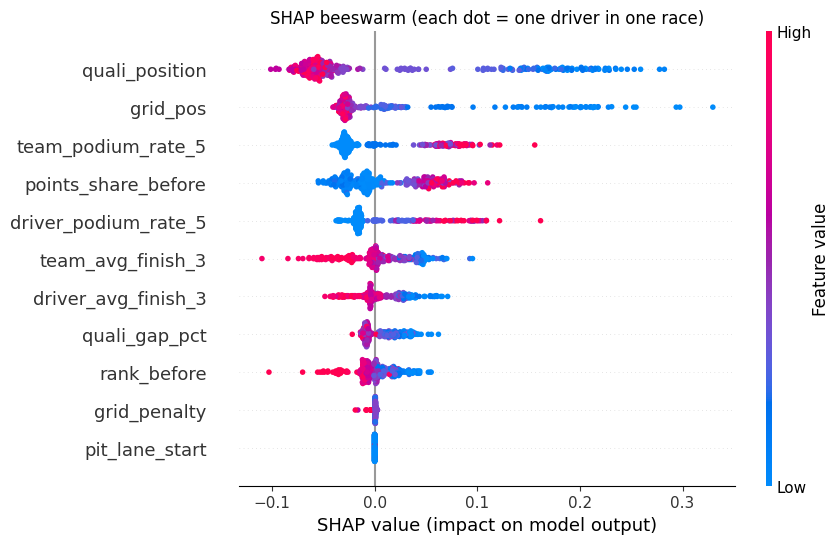

In [52]:
# the function that SHAP will call 
def podium_proba(X):
    X = pd.DataFrame(X, columns=FEATURES) 
    return grad_boost.predict_proba(X)[:, 1]

background = X_train.sample(100, random_state=SEED)   # reference drivers from the training years
explainer  = shap.Explainer(podium_proba, background, seed=SEED)

X_explain   = X_test.sample(300, random_state=SEED)   # unseen races to explain
shap_values = explainer(X_explain, silent=True)       # one SHAP value per row and per feature 

# plot 1: global importance = average size of the SHAP values
shap.plots.bar(shap_values, max_display=len(FEATURES), show=False)
plt.title("SHAP global importance (mean |SHAP value|)")
plt.show()

# plot 2: beeswarm,one dot per driver-race
#   x position = how much the feature pushed this prediction up or down
#   colour = the feature's value (red;high and blue;low)
shap.plots.beeswarm(shap_values, max_display=len(FEATURES), show=False)
plt.title("SHAP beeswarm (each dot = one driver in one race)")
plt.show()

### What this shows
- **Bar plot:** `quali_position` and `grid_pos` contribute the most, followed by `team_podium_rate_5`, `driver_podium_rate_5`, `team_avg_finish_3` and `points_share_before`. The top features are the same as in permutation importance. SHAP gives the form features more weight because it shares credit between correlated features, instead of measuring what is lost when one feature is shuffled.
- **Beeswarm:** the directions make sense in F1 terms:
  - A good starting position pushes the probability up. A bad starting position only pushes it down a little, because most midfield and back-of-grid drivers already have a low probability.
  - A high podium rate for the team or the driver (red) pushes up.
  - A high average finish (red = usually finishing far back) pushes down.
- `grid_penalty` and `pit_lane_start` have almost no effect.

## Local explanation: one single prediction (SHAP waterfall + LIME)

A local explanation answers: why did the model give this driver in this race this probability?

**Which row:** Max Verstappen at the 2023 Saudi Arabian Grand Prix (a test-set race). It is an interesting case because the two kinds of features disagree: he was the fastest driver in Q1 (`quali_gap_pct` = 0) but a car problem later in qualifying left him 15th on the grid, while his driver form, team form and standings were the best in the field. He finished 2nd. We will explain this same row with both SHAP and LIME, so the two methods can be compared.

In [53]:
# find the row of Max Verstappen at the 2023 Saudi Arabian Grand Prix in the test set
race_id   = races.loc[(races["year"] == 2023) & (races["name"] == "Saudi Arabian Grand Prix"), "raceId"].iloc[0]
driver_id = drivers.loc[drivers["driverRef"] == "max_verstappen", "driverId"].iloc[0]
row_id    = test.index[(test["raceId"] == race_id) & (test["driverId"] == driver_id)][0]   # row label in X_test

probability = grad_boost.predict_proba(X_test.loc[[row_id]])[0, 1]
print("Driver: Max Verstappen | Race: 2023 Saudi Arabian Grand Prix")
print(f"Started P{int(test.loc[row_id, 'grid_pos'])} | Actual podium: {bool(test.loc[row_id, 'podium'])} | "
      f"Predicted probability: {probability:.3f} (threshold {gb_threshold:.2f})")

x_row = X_test.loc[[row_id]]          # the row as a 1-row table
display(x_row)

Driver: Max Verstappen | Race: 2023 Saudi Arabian Grand Prix
Started P15 | Actual podium: True | Predicted probability: 0.786 (threshold 0.79)


,quali_position,quali_gap_pct,grid_pos,pit_lane_start,grid_penalty,driver_avg_finish_3,driver_podium_rate_5,team_avg_finish_3,team_podium_rate_5,rank_before,points_share_before
24407,15.0,0.0,15,0,0.0,2.666667,0.8,3.333333,0.7,1.0,1.0


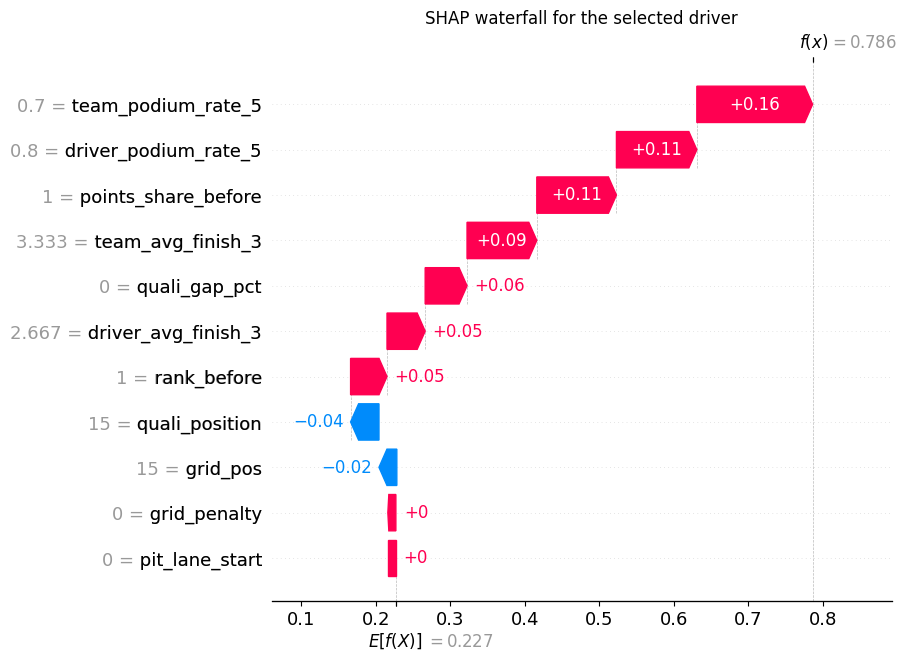

In [54]:
# ---- Local SHAP: waterfall plot ----
# starts from the average prediction E[f(X)] at the bottom, then each bar adds or removes probability
# until we reach this driver's prediction f(x) at the top.
local_shap = explainer(x_row, silent=True)
shap.plots.waterfall(local_shap[0], max_display=len(FEATURES), show=False)
plt.title("SHAP waterfall for the selected driver")
plt.show()

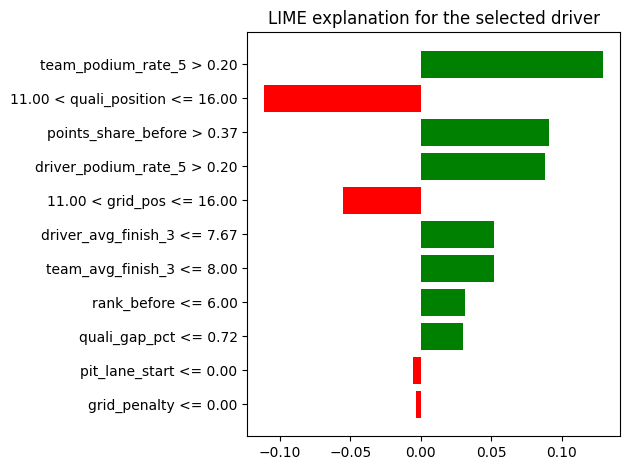

LIME weights (rule -> effect on podium probability):
  team_podium_rate_5 > 0.20                     +0.129
  11.00 < quali_position <= 16.00               -0.111
  points_share_before > 0.37                    +0.091
  driver_podium_rate_5 > 0.20                   +0.088
  11.00 < grid_pos <= 16.00                     -0.055
  driver_avg_finish_3 <= 7.67                   +0.052
  team_avg_finish_3 <= 8.00                     +0.052
  rank_before <= 6.00                           +0.032
  quali_gap_pct <= 0.72                         +0.030
  pit_lane_start <= 0.00                        -0.006
  grid_penalty <= 0.00                          -0.003


In [55]:
# ---- LIME ----
# LIME creates many slightly changed copies of the row, asks the model for their predictions,
# and fits a simple model around this one point. Its weights are the explanation.


lime_train = X_train.fillna(X_train.median())

lime_explainer = LimeTabularExplainer(
    training_data=lime_train.values,
    feature_names=FEATURES,
    class_names=["No podium", "Podium"],
    mode="classification",
    random_state=SEED,
)

# LIME needs a function that returns the probabilities of both classes
def lime_predict(X):
    return grad_boost.predict_proba(pd.DataFrame(X, columns=FEATURES))

lime_exp = lime_explainer.explain_instance(
    x_row.values[0], lime_predict, num_features=len(FEATURES), num_samples=5000)

lime_exp.as_pyplot_figure()          # green = pushes towards podium, red = pushes away
plt.title("LIME explanation for the selected driver")
plt.tight_layout()
plt.show()

print("LIME weights (rule -> effect on podium probability):")
for rule, weight in lime_exp.as_list():
    print(f"  {rule:45s} {weight:+.3f}")

### What this shows
- The average prediction is about 0.23 (`E[f(X)]` in the waterfall). For this driver the model predicts about 0.80, right at the threshold, so it says "podium", and he did finish 2nd.
- **SHAP waterfall:** the probability is pushed up by strong form, with `team_podium_rate_5`, `driver_podium_rate_5`, `team_avg_finish_3` and `points_share_before` adding about +0.10 to +0.15 each, plus `rank_before` = 1 and `quali_gap_pct` = 0 (fastest in Q1). Starting P15 (`quali_position` and `grid_pos`) only pushes it down a little, by about −0.04 and −0.02.
- **LIME** says the same thing: team podium rate, driver podium rate and points share push towards podium, and "quali_position between 11 and 16" is the biggest push away.
- **Difference:** LIME gives the bad starting position a bigger negative weight than SHAP. This is because LIME fits a simple linear model on random changes around this one row, using ranges such as "11 < quali_position ≤ 16", while SHAP splits the model's exact prediction. Both methods agree on the conclusion: strong form outweighed the bad starting position for this prediction.


## Inference function

`predict_podium(record)` takes one driver–race record, given as a dictionary of feature values known after qualifying and before the race and returns:
- the podium probability,
- the yes/no prediction (using the threshold chosen on validation),
- the list of missing features.


In [56]:
def predict_podium(record, model=grad_boost, threshold=gb_threshold):
    # warn about names the model does not know
    unknown = [k for k in record if k not in FEATURES]
    if unknown:
        print("Warning: these keys are not model features and are ignored:", unknown)

    # build a 1-row table with exactly the training columns in the training order.
    # features that are not in the record become NaN
    row = pd.DataFrame([record]).reindex(columns=FEATURES).astype(float)


    missing = [f for f in FEATURES if pd.isna(row.loc[0, f])]

    # predict with the trained pipeline (impute -> scale -> gradient boosting)
    probability = model.predict_proba(row)[0, 1]

    return {
        "podium_probability": round(float(probability), 3),
        "prediction":         "Podium" if probability >= threshold else "No podium",
        "threshold":          round(float(threshold), 2),
        "missing_features":   missing,
    }

### Demo 1: a complete record

The real test-set row explained in 4.6 (Verstappen, 2023 Saudi Arabian GP), with every feature known.

In [57]:
complete_record = X_test.loc[row_id].to_dict()        # real row from 2022-2024 no missing values
print("Input:", {k: round(v, 3) for k, v in complete_record.items()})

result_complete = predict_podium(complete_record)
print("Output:", result_complete)
print("Actual result: ", "Podium" if y_test.loc[row_id] == 1 else "No podium")

Input: {'quali_position': 15.0, 'quali_gap_pct': 0.0, 'grid_pos': 15.0, 'pit_lane_start': 0.0, 'grid_penalty': 0.0, 'driver_avg_finish_3': 2.667, 'driver_podium_rate_5': 0.8, 'team_avg_finish_3': 3.333, 'team_podium_rate_5': 0.7, 'rank_before': 1.0, 'points_share_before': 1.0}
Output: {'podium_probability': 0.786, 'prediction': 'No podium', 'threshold': 0.79, 'missing_features': []}
Actual result:  Podium


### Demo 2: a partially missing record

A realistic case: a rookie in round 1 of the season. Qualifying and grid are known, but there is no driver form (no earlier races) and there are no standings
- the **team form** is known, because the team raced last season.

We only give the known features. Everything else is left out.

In [58]:
rookie_record = {
    "quali_position": 5,       
    "quali_gap_pct": 0.6,      
    "grid_pos": 5,             
    "pit_lane_start": 0,       
    "grid_penalty": 0,         
    "team_avg_finish_3": 6.0,  
    "team_podium_rate_5": 0.2, 
    # driver form and standings are left out -> missing
}

result_rookie = predict_podium(rookie_record)
print("Output:", result_rookie)

Output: {'podium_probability': 0.132, 'prediction': 'No podium', 'threshold': 0.79, 'missing_features': ['driver_avg_finish_3', 'driver_podium_rate_5', 'rank_before', 'points_share_before']}


In [59]:
# summary of both demos
demo = pd.DataFrame([result_complete, result_rookie],
                    index=["Demo 1: complete record", "Demo 2: rookie, round 1 (partially missing)"])
demo["number of missing features"] = demo["missing_features"].apply(len)
display(demo.drop(columns="missing_features"))

,podium_probability,prediction,threshold,number of missing features
Demo 1: complete record,0.786,No podium,0.79,0
"Demo 2: rookie, round 1 (partially missing)",0.132,No podium,0.79,4
